In [1]:
import sys, subprocess, importlib.util
PACKAGES={
    'pytorch_grad_cam':'grad-cam','captum':'captum','lime':'lime',
    'shap':'shap','imblearn':'imbalanced-learn','skimage':'scikit-image'
}
for mod,pkg in PACKAGES.items():
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])

import os,re,gc,math,json,time,random,shutil,hashlib,tarfile,warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, joblib, psutil
from PIL import Image
from tqdm.auto import tqdm
from scipy import stats
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms,models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,balanced_accuracy_score,precision_recall_fscore_support,
    precision_score,recall_score,f1_score,classification_report,confusion_matrix,
    roc_auc_score,roc_curve,precision_recall_curve,average_precision_score,
    cohen_kappa_score,matthews_corrcoef,log_loss,silhouette_score,
    adjusted_rand_score,normalized_mutual_info_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.calibration import calibration_curve
from imblearn.over_sampling import RandomOverSampler
from skimage.feature import graycomatrix,graycoprops
from skimage.segmentation import slic
from pytorch_grad_cam import GradCAM,GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from captum.attr import IntegratedGradients,GradientShap
from lime import lime_image
import shap
from IPython.display import display, FileLink, HTML

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
warnings.filterwarnings('ignore')
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP=torch.cuda.is_available()
plt.rcParams.update({'font.size':16,'axes.titlesize':16,'axes.labelsize':16,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':13,'figure.titlesize':16,'savefig.dpi':400})
print('Device:',DEVICE)
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
print('RAM:',round(psutil.virtual_memory().available/1024**3,2),'GiB')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 16.4 MB/s eta 0:00:00
Device: cuda
GPU: Tesla T4
RAM: 29.55 GiB


In [2]:
# CELL 2 — DATASET INPUT / BINARY FILTER
OUTPUT_DIR=Path('/kaggle/working/tongue_fld_q1_v8_2_ten_models') if Path('/kaggle/working').exists() else Path('./tongue_fld_q1_v8_2_ten_models')
WEIGHT_DIR=OUTPUT_DIR/'weights'; FIG_DIR=OUTPUT_DIR/'figures'; TABLE_DIR=OUTPUT_DIR/'tables'; XAI_DIR=OUTPUT_DIR/'xai'
for p in [OUTPUT_DIR,WEIGHT_DIR,FIG_DIR,TABLE_DIR,XAI_DIR]: p.mkdir(parents=True,exist_ok=True)
CLASS_NAMES=['Non-FLD','Mild FLD']; REGION_NAMES=['Posterior','Left lateral','Center','Right lateral','Tip']

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR/f'{name}.png',dpi=400,bbox_inches='tight'); plt.savefig(FIG_DIR/f'{name}.pdf',bbox_inches='tight'); plt.show()

def locate_dataset():
    for root in [Path('/kaggle/input'),Path('/kaggle/working'),Path('.')]:
        if root.exists():
            hits=list(root.rglob('Indicator_and_Label.csv'))
            if hits: return hits[0]
    repo=Path('/kaggle/working/HM-TDF') if Path('/kaggle/working').exists() else Path('./HM-TDF')
    if not repo.exists(): subprocess.run(['git','clone','--depth','1','https://github.com/MLDMXM2017/HM-TDF.git',str(repo)],check=True)
    return repo/'Tongue-FLD'/'Indicator_and_Label.csv'

CSV_PATH=locate_dataset(); DATA_ROOT=CSV_PATH.parent; IMAGE_DIR=DATA_ROOT/'Tongue_Images'
if not IMAGE_DIR.exists():
    parts=sorted(DATA_ROOT.glob('Tongue_Images.tar.gz.*'))
    if not parts: raise FileNotFoundError('Tongue image archive parts not found.')
    archive=DATA_ROOT/'Tongue_Images.tar.gz'
    with open(archive,'wb') as w:
        for part in parts:
            with open(part,'rb') as r: shutil.copyfileobj(r,w)
    with tarfile.open(archive,'r:gz') as tf: tf.extractall(DATA_ROOT)

full_df=pd.read_csv(CSV_PATH).copy().reset_index(drop=True)
FILE_COL=full_df.columns[0]; RAW_LABEL_COL=full_df.columns[-1]; PHYS_COLS=list(full_df.columns[1:-1])
def encode_label(v):
    s=str(v).strip().lower(); m=re.fullmatch(r'_?([012])(?:\.0)?',s)
    if m: return int(m.group(1))
    t=s.replace('_',' ').replace('-',' ')
    if any(k in t for k in ['non fld','nonfld','no fld','normal']): return 0
    if 'mild' in t: return 1
    if 'moderate' in t or 'severe' in t: return 2
    raise ValueError(v)
full_df['target']=full_df[RAW_LABEL_COL].map(encode_label).astype(int)
df=full_df[full_df.target.isin([0,1])].copy().reset_index(drop=True)
assert df.target.value_counts().sort_index().to_dict()=={0:3690,1:1512}
files=[p for p in IMAGE_DIR.rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp'}]
name_map={p.name:p for p in files}; df['image_path']=df[FILE_COL].astype(str).map(lambda x:name_map.get(Path(x).name))
assert df.image_path.notna().all()
print('Binary rows:',len(df)); print(df.target.value_counts().sort_index()); print('Excluded class-2:',int((full_df.target==2).sum()))

Cloning into '/kaggle/working/HM-TDF'...


Binary rows: 5202
target
0    3690
1    1512
Name: count, dtype: int64
Excluded class-2: 515


In [3]:
# CELL 3 — EXACT-DUPLICATE HASHES (ROBUST / SELF-HEALING)
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

# Use a version-specific cache so malformed/older caches do not break this notebook.
HASH_FILE = OUTPUT_DIR / 'binary_image_hashes.csv'

def rebuild_hash_cache():
    print("Building SHA-256 cache from source images...")
    paths = df["image_path"].astype(str).tolist()
    hashes = [sha256_file(p) for p in tqdm(paths, desc="Hashing")]
    cache = pd.DataFrame({
        "image_path": paths,
        "sha256": hashes
    })
    cache.to_csv(HASH_FILE, index=False)
    return dict(zip(cache["image_path"], cache["sha256"]))

hash_map = None

if HASH_FILE.exists():
    try:
        hdf = pd.read_csv(HASH_FILE)

        # Normalize possible column names from older notebook versions.
        normalized = {str(c).strip().lower(): c for c in hdf.columns}

        path_col = normalized.get("image_path")
        hash_col = normalized.get("sha256")

        # Older notebooks may have stored the same SHA value as "group_hash".
        if hash_col is None:
            hash_col = normalized.get("group_hash")

        cache_ok = (
            path_col is not None
            and hash_col is not None
            and len(hdf) > 0
            and hdf[path_col].notna().any()
            and hdf[hash_col].notna().any()
        )

        if cache_ok:
            print(f"Using valid hash cache: {HASH_FILE}")
            print("Cache columns:", hdf.columns.tolist())
            hash_map = dict(
                zip(
                    hdf[path_col].astype(str),
                    hdf[hash_col].astype(str)
                )
            )
        else:
            print("Existing hash cache has incompatible columns:", hdf.columns.tolist())
            print("Regenerating it automatically...")
            hash_map = rebuild_hash_cache()

    except Exception as e:
        print("Hash cache could not be read:", repr(e))
        print("Regenerating it automatically...")
        hash_map = rebuild_hash_cache()
else:
    hash_map = rebuild_hash_cache()

# Map cached hashes to every image.
df["group_hash"] = df["image_path"].astype(str).map(hash_map)

# If paths changed or some rows were not present in the cache, compute only missing hashes.
missing_hash = df["group_hash"].isna()
if missing_hash.any():
    print(f"Computing {int(missing_hash.sum())} hashes missing from cache...")
    missing_values = [
        sha256_file(p)
        for p in tqdm(df.loc[missing_hash, "image_path"], desc="Hashing missing")
    ]
    df.loc[missing_hash, "group_hash"] = missing_values

    # Save a complete, clean cache for future runs.
    pd.DataFrame({
        "image_path": df["image_path"].astype(str),
        "sha256": df["group_hash"].astype(str)
    }).drop_duplicates("image_path").to_csv(HASH_FILE, index=False)

assert df["group_hash"].notna().all(), "Some image hashes are still missing."

duplicate_rows = int(df.duplicated("group_hash", keep=False).sum())

print("Hash cache:", HASH_FILE)
print("Rows:", len(df))
print("Unique SHA-256 hashes:", df["group_hash"].nunique())
print("Rows involved in exact duplicates:", duplicate_rows)

Building SHA-256 cache from source images...


Hashing:   0%|          | 0/5202 [00:00<?, ?it/s]

Hash cache: /kaggle/working/tongue_fld_q1_v8_2_ten_models/binary_image_hashes.csv
Rows: 5202
Unique SHA-256 hashes: 5202
Rows involved in exact duplicates: 0


In [4]:
# CELL 4 — BINARY 70:20:10 SPLIT, SEED 42
# PDF used splitfolders.ratio(..., seed=42, ratio=(.7,.2,.1)).
y=df.target.to_numpy()
groups=df.group_hash.to_numpy()

# Lock 10% test first.
s_test=StratifiedGroupKFold(n_splits=10,shuffle=True,random_state=SEED)
TRAINVAL_IDX,TEST_IDX=next(s_test.split(df,y,groups))
TRAINVAL_IDX=np.asarray(TRAINVAL_IDX); TEST_IDX=np.asarray(TEST_IDX)

# From remaining 90%, validation should be ~20% of full data.
# 2/9 of 90% ~= 20%; use 9 folds and take two folds as validation.
tv=df.iloc[TRAINVAL_IDX]
s_val=StratifiedGroupKFold(n_splits=9,shuffle=True,random_state=SEED+1)
folds=list(s_val.split(tv,tv.target.to_numpy(),tv.group_hash.to_numpy()))
va_rel=np.concatenate([folds[0][1],folds[1][1]])
va_rel=np.unique(va_rel)
tr_rel=np.setdiff1d(np.arange(len(tv)),va_rel)

TRAIN_IDX=TRAINVAL_IDX[tr_rel]
VAL_IDX=TRAINVAL_IDX[va_rel]

tg=set(df.iloc[TRAIN_IDX].group_hash)
vg=set(df.iloc[VAL_IDX].group_hash)
eg=set(df.iloc[TEST_IDX].group_hash)
assert not(tg&vg) and not(tg&eg) and not(vg&eg)

for name,ids in [("Train",TRAIN_IDX),("Validation",VAL_IDX),("Test",TEST_IDX)]:
    print(name,len(ids),f"{100*len(ids)/len(df):.2f}%",
          np.bincount(df.iloc[ids].target,minlength=2).tolist())

manifest=[]
for role,ids in [("train",TRAIN_IDX),("validation",VAL_IDX),("test",TEST_IDX)]:
    manifest += [{"row_index":int(i),"role":role} for i in ids]
pd.DataFrame(manifest).to_csv(TABLE_DIR/"binary_split_70_20_10_manifest.csv",index=False)

Train 3640 69.97% [2592, 1048]
Validation 1042 20.03% [716, 326]
Test 520 10.00% [382, 138]


In [5]:
# CELL 5 — TRAIN-ONLY EXACT 2000 / 2000 BALANCING
TARGET_PER_CLASS=2000
rng=np.random.default_rng(SEED)
train_y=df.iloc[TRAIN_IDX].target.to_numpy(); c0=TRAIN_IDX[train_y==0]; c1=TRAIN_IDX[train_y==1]
# Exact 2k/class needs majority sampling plus minority random oversampling.
c0_base=rng.choice(c0,TARGET_PER_CLASS,replace=False) if len(c0)>TARGET_PER_CLASS else c0.copy()
base_idx=np.concatenate([c0_base,c1]); base_y=df.iloc[base_idx].target.to_numpy()
ros=RandomOverSampler(sampling_strategy={0:TARGET_PER_CLASS,1:TARGET_PER_CLASS},random_state=SEED)
resampled,_=ros.fit_resample(base_idx.reshape(-1,1),base_y)
TRAIN_BAL_IDX=resampled.ravel().astype(int); rng.shuffle(TRAIN_BAL_IDX)
before=np.bincount(train_y,minlength=2); after=np.bincount(df.iloc[TRAIN_BAL_IDX].target,minlength=2)
assert after.tolist()==[2000,2000]
print('Original train:',before.tolist()); print('Balanced train:',after.tolist()); print('Unique subjects:',len(np.unique(TRAIN_BAL_IDX)))
pd.DataFrame({'class':CLASS_NAMES,'original_train':before,'balanced_train':after}).to_csv(TABLE_DIR/'binary_train_balance.csv',index=False)

Original train: [2592, 1048]
Balanced train: [2000, 2000]
Unique subjects: 3048


In [6]:
# CELL 6 — RAW IMAGE CACHE ONLY: NO CLAHE, NO ROI CROP
IMG_SIZE=275

def read_raw_resized(path):
    bgr=cv2.imread(str(path),cv2.IMREAD_COLOR)
    if bgr is None:
        raise RuntimeError(f"Could not read {path}")
    rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    rgb=cv2.resize(rgb,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_AREA)
    return np.ascontiguousarray(rgb,dtype=np.uint8)

def foreground_mask_from_raw(rgb):
    if rgb is None or rgb.size==0:
        raise ValueError("Empty image supplied to foreground_mask_from_raw().")

    m=(rgb.max(axis=2)>8).astype(np.uint8)
    k=np.ones((5,5),np.uint8)
    m=cv2.morphologyEx(m,cv2.MORPH_CLOSE,k,iterations=2)
    m=cv2.morphologyEx(m,cv2.MORPH_OPEN,k,iterations=1)

    n,lab,st,_=cv2.connectedComponentsWithStats(m,8)
    if n>1:
        largest=1+np.argmax(st[1:,cv2.CC_STAT_AREA])
        m=(lab==largest).astype(np.uint8)

    if m.sum()==0:
        m=np.ones(rgb.shape[:2],dtype=np.uint8)

    return m

def cache_split(indices,name):
    indices=np.asarray(indices,dtype=int)
    images=np.empty(
        (len(indices),IMG_SIZE,IMG_SIZE,3),
        dtype=np.uint8
    )
    masks=np.empty(
        (len(indices),IMG_SIZE,IMG_SIZE),
        dtype=np.uint8
    )

    for j,idx in enumerate(tqdm(indices,desc=f"Cache {name}")):
        rgb=read_raw_resized(df.iloc[int(idx)].image_path)
        images[j]=rgb
        masks[j]=foreground_mask_from_raw(rgb)

    pos={int(i):j for j,i in enumerate(indices)}

    # Both names intentionally point to the same NumPy array.
    # "masks" is canonical; "mask" is retained as a compatibility alias.
    return {
        "indices":indices,
        "pos":pos,
        "images":images,
        "masks":masks,
        "mask":masks,
    }

estimated_gb=len(df)*(IMG_SIZE*IMG_SIZE*4)/1024**3
available_gb=psutil.virtual_memory().available/1024**3
print(
    f"Estimated RAM {estimated_gb:.2f} GiB | "
    f"available {available_gb:.2f} GiB"
)
assert available_gb>estimated_gb+1.0, (
    "Insufficient free RAM for image+mask cache. "
    f"Need about {estimated_gb+1.0:.2f} GiB free."
)

Estimated RAM 1.47 GiB | available 29.48 GiB


In [7]:
# CONTINUATION — BUILD / VALIDATE RAM CACHE
TRAIN_RAM=cache_split(TRAIN_IDX,"train")
VAL_RAM=cache_split(VAL_IDX,"validation")
TEST_RAM=cache_split(TEST_IDX,"test")

RAMS={
    "train":TRAIN_RAM,
    "val":VAL_RAM,
    "test":TEST_RAM
}

ROW_SPLIT={}
for split_name,ids in [
    ("train",TRAIN_IDX),
    ("val",VAL_IDX),
    ("test",TEST_IDX)
]:
    for idx in ids:
        ROW_SPLIT[int(idx)]=split_name

def _get_store(idx):
    idx=int(idx)
    if idx not in ROW_SPLIT:
        raise KeyError(
            f"Row {idx} is not registered in train/validation/test splits."
        )
    return RAMS[ROW_SPLIT[idx]]

def get_raw(idx):
    idx=int(idx)
    st=_get_store(idx)
    pos=st["pos"][idx]
    return st["images"][pos]

def get_mask(idx):
    idx=int(idx)
    st=_get_store(idx)
    pos=st["pos"][idx]

    # Canonical path.
    if "masks" in st:
        return st["masks"][pos]

    # Compatibility with any older in-memory cache.
    if "mask" in st:
        return st["mask"][pos]

    # Last-resort regeneration prevents a DataLoader crash.
    print(f"Warning: mask cache missing for row {idx}; regenerating mask.")
    return foreground_mask_from_raw(get_raw(idx))

# Cache integrity preflight.
for split_name,store in RAMS.items():
    assert "images" in store
    assert "pos" in store
    assert ("masks" in store) or ("mask" in store)

    assert store["images"].ndim==4
    mask_array=store["masks"] if "masks" in store else store["mask"]
    assert mask_array.ndim==3
    assert len(store["images"])==len(mask_array)==len(store["indices"])

# Test actual sample access before later DataLoaders are created.
for probe in [
    int(TRAIN_IDX[0]),
    int(VAL_IDX[0]),
    int(TEST_IDX[0])
]:
    _im=get_raw(probe)
    _mk=get_mask(probe)

    assert _im.shape==(IMG_SIZE,IMG_SIZE,3), _im.shape
    assert _mk.shape==(IMG_SIZE,IMG_SIZE), _mk.shape
    assert _im.dtype==np.uint8
    assert _mk.dtype==np.uint8

print("Raw RAM cache ready.")
print("RAM image/mask integrity preflight: PASSED")

Cache train:   0%|          | 0/3640 [00:00<?, ?it/s]

Cache validation:   0%|          | 0/1042 [00:00<?, ?it/s]

Cache test:   0%|          | 0/520 [00:00<?, ?it/s]

Raw RAM cache ready.
RAM image/mask integrity preflight: PASSED


In [8]:
# CELL 7 — RAW-IMAGE TRAINING SETTINGS
BATCH_SIZE=32; EPOCHS=20; PATIENCE=5; LR_BACKBONE=3e-5; LR_HEAD=3e-4; WEIGHT_DECAY=1e-4; DROPOUT=.60; FREEZE_BACKBONE_EPOCHS=2
TRAIN_TF=transforms.Compose([
    transforms.RandomAffine(degrees=0,scale=(.5,1.5),shear=(-.5,.5),fill=0),
    transforms.RandomHorizontalFlip(p=.5),transforms.ToTensor(),
    transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
EVAL_TF=transforms.Compose([transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
print({'classes':CLASS_NAMES,'image_size':IMG_SIZE,'batch':BATCH_SIZE,'clahe':False,'roi_crop':False,'smote':False,'balance':'2000/2000 train only'})

{'classes': ['Non-FLD', 'Mild FLD'], 'image_size': 275, 'batch': 32, 'clahe': False, 'roi_crop': False, 'smote': False, 'balance': '2000/2000 train only'}


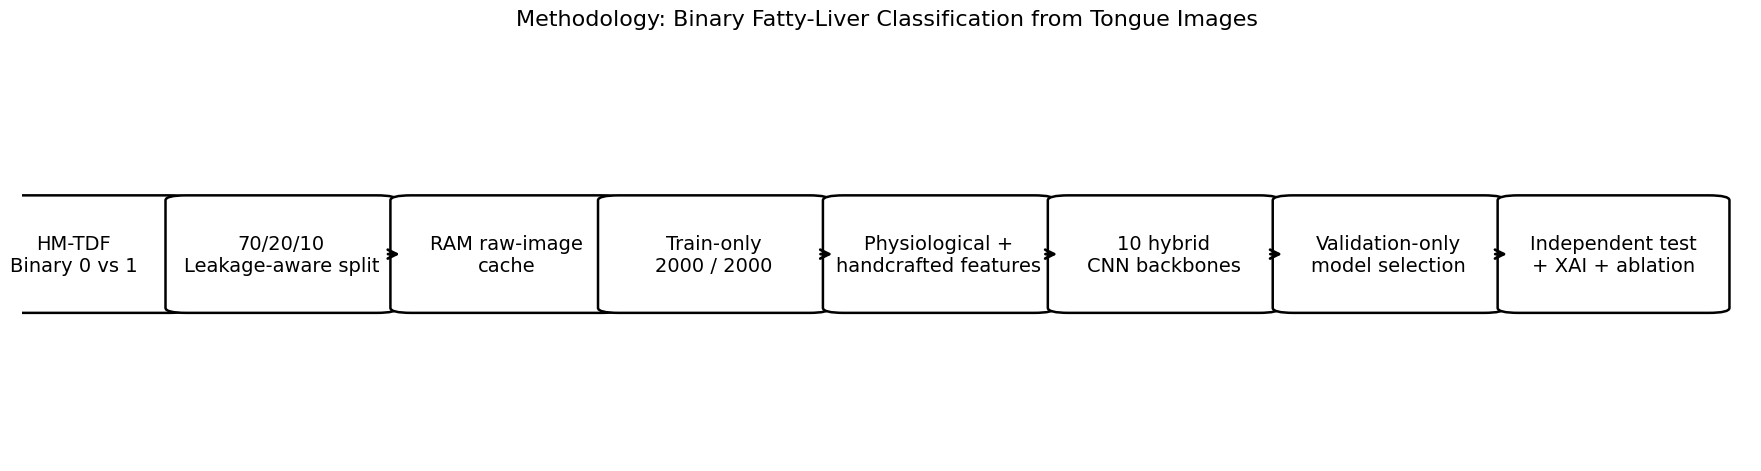

In [9]:
# METHODOLOGY DIAGRAM — 400 DPI PAPER FIGURE
from matplotlib.patches import FancyBboxPatch

fig,ax=plt.subplots(figsize=(18,5))
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.axis("off")

steps=[
    ("HM-TDF\nBinary 0 vs 1",.03),
    ("70/20/10\nLeakage-aware split",.15),
    ("RAM raw-image\ncache",.28),
    ("Train-only\n2000 / 2000",.40),
    ("Physiological +\nhandcrafted features",.53),
    ("10 hybrid\nCNN backbones",.66),
    ("Validation-only\nmodel selection",.79),
    ("Independent test\n+ XAI + ablation",.92),
]

for label,x in steps:
    box=FancyBboxPatch(
        (x-.055,.37),.11,.26,
        boxstyle="round,pad=0.012",
        linewidth=1.8,
        facecolor="white",
        edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(x,.50,label,ha="center",va="center",fontsize=14)

for (_,x1),(_,x2) in zip(steps[:-1],steps[1:]):
    ax.annotate(
        "",
        xy=(x2-.06,.50),
        xytext=(x1+.06,.50),
        arrowprops=dict(arrowstyle="->",lw=2)
    )

ax.set_title(
    "Methodology: Binary Fatty-Liver Classification from Tongue Images",
    fontsize=16,
    pad=16
)
savefig("00_methodology_diagram")

In [10]:
# CELL 8 — PHYSIOLOGICAL + RAW HANDCRAFTED FEATURES
def make_phys_preprocessor(train_idx):
    frame=df.iloc[train_idx]; numeric=[c for c in PHYS_COLS if pd.api.types.is_numeric_dtype(frame[c])]; categorical=[c for c in PHYS_COLS if c not in numeric]
    try: ohe=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError: ohe=OneHotEncoder(handle_unknown='ignore',sparse=False)
    return ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),numeric),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',ohe)]),categorical)])
PHYS_PREP=make_phys_preprocessor(TRAIN_IDX); PHYS_PREP.fit(df.iloc[TRAIN_IDX][PHYS_COLS])
PHYS=np.zeros((len(df),PHYS_PREP.transform(df.iloc[TRAIN_IDX[:1]][PHYS_COLS]).shape[1]),dtype=np.float32)
for ids in [TRAIN_IDX,VAL_IDX,TEST_IDX]: PHYS[ids]=PHYS_PREP.transform(df.iloc[ids][PHYS_COLS]).astype(np.float32)
joblib.dump(PHYS_PREP,WEIGHT_DIR/'phys_preprocessor.joblib')
HAND_NAMES=['r_mean','g_mean','b_mean','r_std','g_std','b_std','h_mean','s_mean','v_mean','entropy','lap_var','edge_density','contrast','homogeneity','energy','correlation','area_ratio','aspect','solidity','perimeter']
def raw_hand_features(rgb):
    mask=foreground_mask_from_raw(rgb).astype(bool); pix=rgb[mask].astype(np.float32)
    if len(pix)==0: pix=rgb.reshape(-1,3).astype(np.float32)
    mu,sd=pix.mean(0),pix.std(0); hsv=cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)[mask].astype(np.float32); hsv_mu=hsv.mean(0) if len(hsv) else np.zeros(3,dtype=np.float32)
    gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY); gp=gray[mask] if mask.any() else gray.ravel(); hist=np.bincount(gp.astype(np.uint8),minlength=256).astype(float); hist/=hist.sum()+1e-9
    ent=float(-(hist[hist>0]*np.log2(hist[hist>0])).sum()); lapmap=cv2.Laplacian(gray,cv2.CV_64F); lap=float(lapmap[mask].var()) if mask.any() else float(lapmap.var()); edge=float((cv2.Canny(gray,50,150)>0)[mask].mean()) if mask.any() else 0.0
    q=(cv2.resize(gray,(64,64))//16).astype(np.uint8); gl=graycomatrix(q,[1],[0,np.pi/4,np.pi/2,3*np.pi/4],levels=16,symmetric=True,normed=True); props=[float(graycoprops(gl,p).mean()) for p in ['contrast','homogeneity','energy','correlation']]
    cnts,_=cv2.findContours(mask.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        cnt=max(cnts,key=cv2.contourArea); hull=cv2.convexHull(cnt); solidity=cv2.contourArea(cnt)/(cv2.contourArea(hull)+1e-9); perimeter=cv2.arcLength(cnt,True)/(4*IMG_SIZE)
    else: solidity=0.; perimeter=0.
    ys,xs=np.where(mask); aspect=(xs.max()-xs.min()+1)/(ys.max()-ys.min()+1+1e-9) if len(xs) else 1.
    return np.nan_to_num(np.r_[mu,sd,hsv_mu,ent,lap,edge,props,[mask.mean(),aspect,solidity,perimeter]].astype(np.float32))

In [11]:
# CELL 9 — EXTRACT / SCALE RAW HANDCRAFTED FEATURES
HAND=np.zeros((len(df),len(HAND_NAMES)),dtype=np.float32)
for ids in [TRAIN_IDX,VAL_IDX,TEST_IDX]:
    for idx in tqdm(ids,desc='Raw handcrafted features'): HAND[idx]=raw_hand_features(get_raw(idx))
HAND_SCALER=StandardScaler().fit(HAND[TRAIN_IDX])
for ids in [TRAIN_IDX,VAL_IDX,TEST_IDX]: HAND[ids]=HAND_SCALER.transform(HAND[ids]).astype(np.float32)
joblib.dump(HAND_SCALER,WEIGHT_DIR/'raw_hand_scaler.joblib')

Raw handcrafted features:   0%|          | 0/3640 [00:00<?, ?it/s]

Raw handcrafted features:   0%|          | 0/1042 [00:00<?, ?it/s]

Raw handcrafted features:   0%|          | 0/520 [00:00<?, ?it/s]

['/kaggle/working/tongue_fld_q1_v8_2_ten_models/weights/raw_hand_scaler.joblib']

In [12]:
# CELL 10 — ROI SEGMENTATION MODEL (ODD-SIZE SAFE)
class DC(nn.Module):
    def __init__(self,a,b):
        super().__init__()
        self.m=nn.Sequential(
            nn.Conv2d(a,b,3,padding=1,bias=False),nn.BatchNorm2d(b),nn.ReLU(inplace=True),
            nn.Conv2d(b,b,3,padding=1,bias=False),nn.BatchNorm2d(b),nn.ReLU(inplace=True))
    def forward(self,x):
        return self.m(x)

def align_to(x,reference):
    # Explicitly align decoder feature maps to skip tensors.
    # Required for odd input sizes such as 275x275.
    if x.shape[-2:] != reference.shape[-2:]:
        x=F.interpolate(x,size=reference.shape[-2:],mode="bilinear",align_corners=False)
    return x

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1,self.e2,self.e3=DC(3,16),DC(16,32),DC(32,64)
        self.bot=DC(64,128)
        self.pool=nn.MaxPool2d(2)
        self.u3=nn.ConvTranspose2d(128,64,2,2); self.d3=DC(128,64)
        self.u2=nn.ConvTranspose2d(64,32,2,2); self.d2=DC(64,32)
        self.u1=nn.ConvTranspose2d(32,16,2,2); self.d1=DC(32,16)
        self.out=nn.Conv2d(16,1,1)

    def forward(self,x):
        input_hw=x.shape[-2:]

        a=self.e1(x)
        b=self.e2(self.pool(a))
        c=self.e3(self.pool(b))
        z=self.bot(self.pool(c))

        z=align_to(self.u3(z),c)
        z=self.d3(torch.cat([z,c],1))

        z=align_to(self.u2(z),b)
        z=self.d2(torch.cat([z,b],1))

        z=align_to(self.u1(z),a)
        z=self.d1(torch.cat([z,a],1))

        z=self.out(z)
        if z.shape[-2:] != input_hw:
            z=F.interpolate(z,size=input_hw,mode="bilinear",align_corners=False)
        return z

class SegDS(Dataset):
    def __init__(self,ids):
        self.ids=np.asarray(ids,dtype=int)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self,k):
        idx=int(self.ids[k])
        rgb=get_raw(idx)
        m=get_mask(idx)

        if rgb.shape!=(IMG_SIZE,IMG_SIZE,3):
            raise RuntimeError(
                f"Unexpected image shape for row {idx}: {rgb.shape}"
            )
        if m.shape!=(IMG_SIZE,IMG_SIZE):
            raise RuntimeError(
                f"Unexpected mask shape for row {idx}: {m.shape}"
            )

        x=EVAL_TF(Image.fromarray(rgb,mode="RGB"))
        y=torch.from_numpy(
            np.ascontiguousarray(m[None])
        ).float()

        return x,y,idx

def dice_loss(z,y):
    if z.shape[-2:] != y.shape[-2:]:
        z=F.interpolate(z,size=y.shape[-2:],mode="bilinear",align_corners=False)
    p=torch.sigmoid(z)
    inter=(p*y).sum((1,2,3))
    den=p.sum((1,2,3))+y.sum((1,2,3))
    return 1-((2*inter+1e-6)/(den+1e-6)).mean()

In [13]:
# CONTINUATION — SEGMENTATION STRUCTURAL PREFLIGHT
# Structural preflight before expensive segmentation training.
with torch.no_grad():
    _seg_test=TinyUNet()
    _dummy=torch.randn(2,3,IMG_SIZE,IMG_SIZE)
    _out=_seg_test(_dummy)
    assert _out.shape==(2,1,IMG_SIZE,IMG_SIZE), (_out.shape,IMG_SIZE)
print("U-Net preflight OK:",tuple(_out.shape))
del _seg_test,_dummy,_out

# Dataset/DataLoader-level preflight catches RAM-key and shape problems
# before starting segmentation training.
_seg_ds_probe=SegDS(TRAIN_IDX[:min(3,len(TRAIN_IDX))])
for _k in range(len(_seg_ds_probe)):
    _x,_y,_idx=_seg_ds_probe[_k]
    assert _x.shape==(3,IMG_SIZE,IMG_SIZE), (_idx,_x.shape)
    assert _y.shape==(1,IMG_SIZE,IMG_SIZE), (_idx,_y.shape)
    assert torch.isfinite(_x).all()
    assert torch.isfinite(_y).all()

print("Segmentation Dataset preflight OK.")
del _seg_ds_probe,_x,_y,_idx


U-Net preflight OK: (2, 1, 275, 275)
Segmentation Dataset preflight OK.


In [14]:
# CELL 11 — SEGMENTATION TRAIN / VALIDATION / TEST
SEG_MODEL=TinyUNet().to(DEVICE)
seg_tr=DataLoader(SegDS(TRAIN_IDX),32,shuffle=True,num_workers=0,pin_memory=True)
seg_va=DataLoader(SegDS(VAL_IDX),64,shuffle=False,num_workers=0,pin_memory=True)
seg_te=DataLoader(SegDS(TEST_IDX),64,shuffle=False,num_workers=0,pin_memory=True)
opt=torch.optim.Adam(SEG_MODEL.parameters(),lr=1e-3)


# Full DataLoader preflight.
_probe_x,_probe_y,_probe_ids=next(iter(seg_tr))
assert _probe_x.ndim==4 and _probe_x.shape[1:]==(3,IMG_SIZE,IMG_SIZE)
assert _probe_y.ndim==4 and _probe_y.shape[1:]==(1,IMG_SIZE,IMG_SIZE)

with torch.no_grad():
    _probe_z=SEG_MODEL(_probe_x[:2].to(DEVICE)).cpu()

assert _probe_z.shape[-2:]==_probe_y[:2].shape[-2:]
print(
    "Segmentation loader/model preflight:",
    "x",tuple(_probe_x.shape),
    "y",tuple(_probe_y.shape),
    "z",tuple(_probe_z.shape)
)

del _probe_x,_probe_y,_probe_ids,_probe_z


best=-1.0
wait=0
hist=[]

def batch_seg_metrics(logits,y):
    if logits.shape[-2:] != y.shape[-2:]:
        logits=F.interpolate(logits,size=y.shape[-2:],mode="bilinear",align_corners=False)
    p=(torch.sigmoid(logits)>=.5).float()
    inter=(p*y).sum((1,2,3))
    union=((p+y)>0).float().sum((1,2,3))
    dice=((2*inter+1e-6)/(p.sum((1,2,3))+y.sum((1,2,3))+1e-6)).mean()
    iou=((inter+1e-6)/(union+1e-6)).mean()
    return float(dice.item()),float(iou.item())

for ep in range(8):
    SEG_MODEL.train()
    losses=[]
    for x,y,_ in seg_tr:
        x,y=x.to(DEVICE),y.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        z=SEG_MODEL(x)
        if z.shape[-2:] != y.shape[-2:]:
            z=F.interpolate(z,size=y.shape[-2:],mode="bilinear",align_corners=False)
        loss=F.binary_cross_entropy_with_logits(z,y)+dice_loss(z,y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(SEG_MODEL.parameters(),5.0)
        opt.step()
        losses.append(float(loss.item()))

    SEG_MODEL.eval()
    vd=[]; vi=[]
    with torch.no_grad():
        for x,y,_ in seg_va:
            d,i=batch_seg_metrics(SEG_MODEL(x.to(DEVICE)),y.to(DEVICE))
            vd.append(d); vi.append(i)

    val_dice=float(np.mean(vd))
    val_iou=float(np.mean(vi))
    hist.append([ep+1,float(np.mean(losses)),val_dice,val_iou])
    print(f"SEG E{ep+1:02d}: loss={np.mean(losses):.4f} valDice={val_dice:.4f} valIoU={val_iou:.4f}")

    if val_dice>best+1e-5:
        best=val_dice
        wait=0
        torch.save(SEG_MODEL.state_dict(),WEIGHT_DIR/"binary_tiny_unet.pt")
    else:
        wait+=1
        if wait>=3:
            print("Segmentation early stopping.")
            break

SEG_MODEL.load_state_dict(torch.load(WEIGHT_DIR/"binary_tiny_unet.pt",map_location=DEVICE))
SEG_MODEL.eval()
td=[]; ti=[]
with torch.no_grad():
    for x,y,_ in seg_te:
        d,i=batch_seg_metrics(SEG_MODEL(x.to(DEVICE)),y.to(DEVICE))
        td.append(d); ti.append(i)

seg_test_result={"dice":float(np.mean(td)),"iou":float(np.mean(ti))}
pd.DataFrame(hist,columns=["epoch","loss","val_dice","val_iou"]).to_csv(
    TABLE_DIR/"segmentation_history.csv",index=False
)
pd.DataFrame([seg_test_result]).to_csv(
    TABLE_DIR/"segmentation_test_metrics.csv",index=False
)
print("Segmentation test:",seg_test_result)

Segmentation loader/model preflight: x (32, 3, 275, 275) y (32, 1, 275, 275) z (2, 1, 275, 275)
SEG E01: loss=0.3211 valDice=0.9992 valIoU=0.9984
SEG E02: loss=0.1111 valDice=0.9993 valIoU=0.9986
SEG E03: loss=0.0503 valDice=0.9994 valIoU=0.9988
SEG E04: loss=0.0280 valDice=0.9995 valIoU=0.9990
SEG E05: loss=0.0181 valDice=0.9995 valIoU=0.9990
SEG E06: loss=0.0128 valDice=0.9995 valIoU=0.9991
SEG E07: loss=0.0096 valDice=0.9996 valIoU=0.9992
SEG E08: loss=0.0075 valDice=0.9996 valIoU=0.9992
Segmentation test: {'dice': 0.9996312459309896, 'iou': 0.9992628229988946}


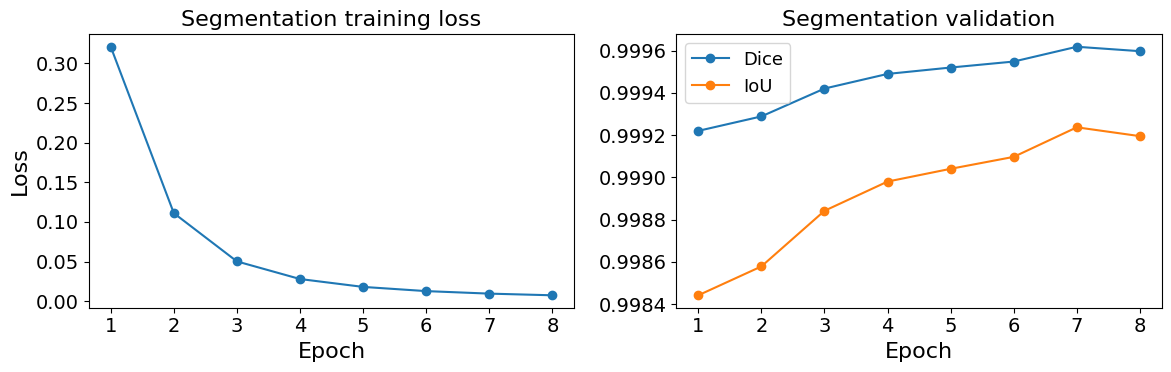

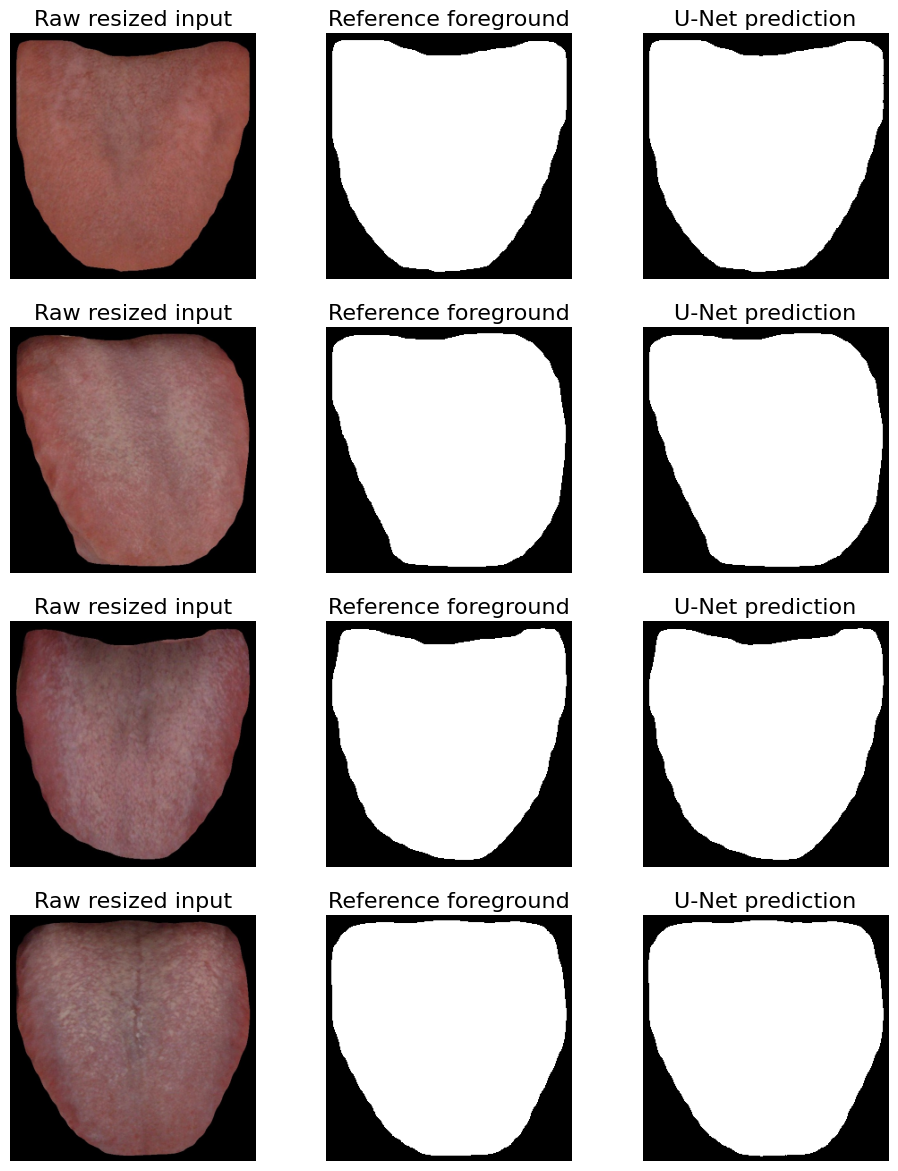

In [15]:
# CELL 11B — SEGMENTATION FIGURES
sh=pd.read_csv(TABLE_DIR/'segmentation_history.csv')
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(sh.epoch,sh.loss,marker='o'); ax[0].set_title('Segmentation training loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
ax[1].plot(sh.epoch,sh.val_dice,marker='o',label='Dice'); ax[1].plot(sh.epoch,sh.val_iou,marker='o',label='IoU'); ax[1].set_title('Segmentation validation'); ax[1].set_xlabel('Epoch'); ax[1].legend(); savefig('segmentation_learning_curves')
xb,yb,idsb=next(iter(seg_te)); SEG_MODEL.eval()
with torch.no_grad(): pb=(torch.sigmoid(SEG_MODEL(xb.to(DEVICE)))>=.5).cpu().numpy()
fig,ax=plt.subplots(4,3,figsize=(10,12))
for r in range(min(4,len(xb))):
    img=xb[r].permute(1,2,0).numpy()*np.array([.229,.224,.225])+np.array([.485,.456,.406]); ax[r,0].imshow(np.clip(img,0,1)); ax[r,0].set_title('Raw resized input'); ax[r,1].imshow(yb[r,0],cmap='gray'); ax[r,1].set_title('Reference foreground'); ax[r,2].imshow(pb[r,0],cmap='gray'); ax[r,2].set_title('U-Net prediction')
    for a in ax[r]: a.axis('off')
savefig('segmentation_examples')

In [16]:
MODEL_NAMES=[
    "BinaryHybrid_MobileNetV3",
    "BinaryHybrid_EfficientNetB0",
    "BinaryHybrid_ResNet18",
    "BinaryHybrid_ShuffleNetV2",
    "BinaryHybrid_RegNetY400",
    "BinaryHybrid_EfficientNetV2S",
    "BinaryHybrid_ConvNeXtTiny",
    "BinaryHybrid_DenseNet121",
    "BinaryHybrid_ResNet50",
    "BinaryHybrid_RegNetY800",
]
BACKBONE_MAP={
    "BinaryHybrid_MobileNetV3":"mobilenet_v3_large",
    "BinaryHybrid_EfficientNetB0":"efficientnet_b0",
    "BinaryHybrid_ResNet18":"resnet18",
    "BinaryHybrid_ShuffleNetV2":"shufflenet_v2_x1_0",
    "BinaryHybrid_RegNetY400":"regnet_y_400mf",
    "BinaryHybrid_EfficientNetV2S":"efficientnet_v2_s",
    "BinaryHybrid_ConvNeXtTiny":"convnext_tiny",
    "BinaryHybrid_DenseNet121":"densenet121",
    "BinaryHybrid_ResNet50":"resnet50",
    "BinaryHybrid_RegNetY800":"regnet_y_800mf",
}
def safe_torchvision_model(builder,enum=None):
    try:
        return builder(weights=enum.DEFAULT if enum is not None else "DEFAULT")
    except Exception as e:
        print(f"Pretrained fallback for {builder.__name__}: {type(e).__name__}: {e}")
        return builder(weights=None)
class Backbone(nn.Module):
    def __init__(self,name):
        super().__init__()
        self.name=name
        self.target_layer=None
        if name=="mobilenet_v3_large":
            b=safe_torchvision_model(
                models.mobilenet_v3_large,
                getattr(models,"MobileNet_V3_Large_Weights",None)
            )
            self.features=b.features; self.channels=b.classifier[0].in_features
        elif name in {"efficientnet_b0","efficientnet_v2_s"}:
            if name=="efficientnet_b0":
                builder=models.efficientnet_b0
                enum=getattr(models,"EfficientNet_B0_Weights",None)
            else:
                builder=models.efficientnet_v2_s
                enum=getattr(models,"EfficientNet_V2_S_Weights",None)
            b=safe_torchvision_model(builder,enum)
            self.features=b.features; self.channels=b.classifier[1].in_features
        elif name in {"resnet18","resnet50"}:
            if name=="resnet18":
                builder=models.resnet18; enum=getattr(models,"ResNet18_Weights",None)
            else:
                builder=models.resnet50; enum=getattr(models,"ResNet50_Weights",None)
            b=safe_torchvision_model(builder,enum)
            self.features=nn.Sequential(
                b.conv1,b.bn1,b.relu,b.maxpool,b.layer1,b.layer2,b.layer3,b.layer4
            )
            self.channels=b.fc.in_features
        elif name=="shufflenet_v2_x1_0":
            b=safe_torchvision_model(
                models.shufflenet_v2_x1_0,
                getattr(models,"ShuffleNet_V2_X1_0_Weights",None)
            )
            self.features=nn.Sequential(
                b.conv1,b.maxpool,b.stage2,b.stage3,b.stage4,b.conv5
            )
            self.channels=b.fc.in_features
        elif name in {"regnet_y_400mf","regnet_y_800mf"}:
            if name=="regnet_y_400mf":
                builder=models.regnet_y_400mf
                enum=getattr(models,"RegNet_Y_400MF_Weights",None)
            else:
                builder=models.regnet_y_800mf
                enum=getattr(models,"RegNet_Y_800MF_Weights",None)
            b=safe_torchvision_model(builder,enum)
            self.features=nn.Sequential(b.stem,b.trunk_output)
            self.channels=b.fc.in_features
        elif name=="convnext_tiny":
            b=safe_torchvision_model(
                models.convnext_tiny,
                getattr(models,"ConvNeXt_Tiny_Weights",None)
            )
            self.features=b.features; self.channels=b.classifier[2].in_features
        elif name=="densenet121":
            b=safe_torchvision_model(
                models.densenet121,
                getattr(models,"DenseNet121_Weights",None)
            )
            self.features=nn.Sequential(b.features,nn.ReLU(inplace=True))
            self.channels=b.classifier.in_features
            self.target_layer=b.features.denseblock4
        else:
            raise ValueError(name)
        if self.target_layer is None:
            self.target_layer=self.features[-1]
    def forward(self,x):
        return self.features(x)

In [17]:
# CELL 13 — BINARY HYBRID CLASSIFIER
class BinaryHybridNet(nn.Module):
    def __init__(self,backbone,phys_dim,hand_dim,use_phys=True,use_hand=True,use_region=True):
        super().__init__(); self.backbone=Backbone(backbone); C=self.backbone.channels; self.pool=nn.AdaptiveAvgPool2d(1)
        self.use_phys=bool(use_phys); self.use_hand=bool(use_hand); self.use_region=bool(use_region)
        self.region_score=nn.Sequential(nn.LayerNorm(C),nn.Linear(C,1)); self.phys=nn.Sequential(nn.Linear(phys_dim,32),nn.ReLU()); self.hand=nn.Sequential(nn.Linear(hand_dim,32),nn.ReLU())
        dim=C+(C if self.use_region else 0)+(32 if self.use_phys else 0)+(32 if self.use_hand else 0)
        self.fusion=nn.Sequential(nn.Linear(dim,128),nn.ReLU(),nn.Dropout(DROPOUT),nn.Linear(128,64),nn.ReLU(),nn.Dropout(DROPOUT)); self.classifier=nn.Linear(64,2)
    def regions(self,f):
        _,_,h,w=f.shape; h1,h2=max(1,h//3),max(2,2*h//3); w1,w2=max(1,3*w//10),max(2,7*w//10); rs=[f[:,:,:h1,:],f[:,:,h1:h2,:w1],f[:,:,h1:h2,w1:w2],f[:,:,h1:h2,w2:],f[:,:,h2:,:]]; g=self.pool(f).flatten(1)
        return torch.stack([g if r.shape[-2]==0 or r.shape[-1]==0 else self.pool(r).flatten(1) for r in rs],1)
    def forward(self,x,p,h):
        f=self.backbone(x); parts=[self.pool(f).flatten(1)]; att=None
        if self.use_region:
            rv=self.regions(f); att=torch.softmax(self.region_score(rv).squeeze(-1),1); parts.append((rv*att.unsqueeze(-1)).sum(1))
        if self.use_phys: parts.append(self.phys(p.float()))
        if self.use_hand: parts.append(self.hand(h.float()))
        emb=self.fusion(torch.cat(parts,1)); return self.classifier(emb),att,emb

In [18]:
# CELL 14 — BINARY DATASET / LOADERS / METRICS
class BinaryDS(Dataset):
    def __init__(self,ids,train=False,phys=None,hand=None): self.ids=np.asarray(ids,dtype=int); self.tf=TRAIN_TF if train else EVAL_TF; self.phys=PHYS if phys is None else phys; self.hand=HAND if hand is None else hand
    def __len__(self): return len(self.ids)
    def __getitem__(self,k):
        idx=int(self.ids[k]); x=self.tf(Image.fromarray(get_raw(idx))); return x,torch.tensor(self.phys[idx],dtype=torch.float32),torch.tensor(self.hand[idx],dtype=torch.float32),torch.tensor(int(df.iloc[idx].target),dtype=torch.long),idx

def make_loaders(balanced=True,phys=None,hand=None,train_ids=None):
    tr=TRAIN_BAL_IDX if balanced else TRAIN_IDX
    if train_ids is not None: tr=np.asarray(train_ids,dtype=int)
    return DataLoader(BinaryDS(tr,True,phys,hand),BATCH_SIZE,shuffle=True),DataLoader(BinaryDS(VAL_IDX,False,phys,hand),BATCH_SIZE*2,shuffle=False),DataLoader(BinaryDS(TEST_IDX,False,phys,hand),BATCH_SIZE*2,shuffle=False)

def binary_metrics(y,probs):
    y=np.asarray(y,dtype=int)
    probs=np.asarray(probs,dtype=float)
    probs=np.clip(np.nan_to_num(probs,nan=.5),1e-8,1)
    probs/=probs.sum(1,keepdims=True)+1e-12

    pred=probs.argmax(1)
    mp,mr,mf,_=precision_recall_fscore_support(
        y,pred,average="macro",zero_division=0
    )

    tn,fp,fn,tp=confusion_matrix(
        y,pred,labels=[0,1]
    ).ravel()

    sensitivity=tp/(tp+fn+1e-12)
    specificity=tn/(tn+fp+1e-12)
    npv=tn/(tn+fn+1e-12)
    fpr=fp/(fp+tn+1e-12)
    fnr=fn/(fn+tp+1e-12)
    youden=sensitivity+specificity-1.0
    brier=float(np.mean((probs[:,1]-y)**2))

    return {
        "accuracy":float(accuracy_score(y,pred)),
        "balanced_accuracy":float(balanced_accuracy_score(y,pred)),
        "macro_precision":float(mp),
        "macro_recall":float(mr),
        "macro_f1":float(mf),
        "precision_class1":float(
            precision_score(y,pred,pos_label=1,zero_division=0)
        ),
        "recall_sensitivity_class1":float(sensitivity),
        "specificity_class0":float(specificity),
        "f1_class1":float(
            f1_score(y,pred,pos_label=1,zero_division=0)
        ),
        "npv_class0":float(npv),
        "false_positive_rate":float(fpr),
        "false_negative_rate":float(fnr),
        "youden_j":float(youden),
        "roc_auc":float(roc_auc_score(y,probs[:,1])),
        "average_precision":float(
            average_precision_score(y,probs[:,1])
        ),
        "kappa":float(cohen_kappa_score(y,pred)),
        "mcc":float(matthews_corrcoef(y,pred)),
        "brier_score":brier,
        "log_loss":float(
            log_loss(y,probs,labels=[0,1])
        )
    }

@torch.no_grad()
def predict_loader(model,loader,return_embedding=False):
    model.eval(); ys=[]; ps=[]; ids=[]; at=[]; em=[]
    for x,p,h,y,idx in loader:
        logits,a,e=model(x.to(DEVICE),p.to(DEVICE),h.to(DEVICE)); ps.append(torch.softmax(logits,1).cpu().numpy()); ys.extend(y.numpy()); ids.extend(idx.numpy());
        if a is not None: at.append(a.cpu().numpy())
        if return_embedding: em.append(e.cpu().numpy())
    return np.asarray(ys),np.vstack(ps),np.asarray(ids),(np.vstack(at) if at else None),(np.vstack(em) if em else None)

In [19]:
# CELL 15 — END-TO-END TRAINING ENGINE
def train_model(
    model_name,
    balanced=True,
    use_region=True,
    use_phys=True,
    use_hand=True,
    epochs=EPOCHS,
    patience=PATIENCE,
    tag=None
):
    tr,va,te=make_loaders(balanced=balanced)
    model=BinaryHybridNet(
        BACKBONE_MAP[model_name],
        PHYS.shape[1],
        HAND.shape[1],
        use_phys,use_hand,use_region
    ).to(DEVICE)
    for p in model.backbone.parameters():
        p.requires_grad=False
    opt=torch.optim.Adam(
        [
            {"params":model.backbone.parameters(),"lr":LR_BACKBONE},
            {
                "params":[
                    p for n,p in model.named_parameters()
                    if not n.startswith("backbone.")
                ],
                "lr":LR_HEAD
            }
        ],
        weight_decay=WEIGHT_DECAY
    )
    scaler=torch.cuda.amp.GradScaler(enabled=AMP)
    ckpt=WEIGHT_DIR/f"{tag or model_name}_best.pt"
    best=-1.0
    wait=0
    hist=[]
    for ep in range(epochs):
        if ep==FREEZE_BACKBONE_EPOCHS:
            for p in model.backbone.parameters():
                p.requires_grad=True
        model.train()
        losses=[]; ty=[]; tp=[]
        for x,p,h,y,_ in tr:
            x,p,h,y=x.to(DEVICE),p.to(DEVICE),h.to(DEVICE),y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=AMP):
                logits,_,_=model(x,p,h)
                loss=F.cross_entropy(logits,y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(),5)
            scaler.step(opt)
            scaler.update()
            losses.append(loss.item())
            ty.extend(y.detach().cpu().numpy())
            tp.append(torch.softmax(logits.detach(),1).cpu().numpy())
        tm=binary_metrics(np.asarray(ty),np.vstack(tp))
        vy,vp,_,_,_=predict_loader(model,va)
        vm=binary_metrics(vy,vp)
        row={
            "epoch":ep+1,
            "loss":float(np.mean(losses)),
            "overfit_gap":tm["macro_f1"]-vm["macro_f1"]
        }
        row.update({f"train_{k}":v for k,v in tm.items()})
        row.update({f"val_{k}":v for k,v in vm.items()})
        hist.append(row)
        print(
            f"{tag or model_name} E{ep+1:02d}: "
            f"trainF1={tm['macro_f1']:.4f} "
            f"valF1={vm['macro_f1']:.4f} "
            f"valAcc={vm['accuracy']:.4f} "
            f"valAUC={vm['roc_auc']:.4f}"
        )
        if vm["macro_f1"]>best+1e-4:
            best=vm["macro_f1"]
            wait=0
            torch.save({
                "model":model.state_dict(),
                "epoch":ep+1,
                "val_metrics":vm,
                "model_name":model_name
            },ckpt)
        else:
            wait+=1
            if wait>=patience:
                print("Early stopping.")
                break
    hist=pd.DataFrame(hist)
    hist.to_csv(
        TABLE_DIR/f"{tag or model_name}_history.csv",
        index=False
    )
    state=torch.load(ckpt,map_location=DEVICE)
    model.load_state_dict(state["model"])
    return model,ckpt,hist,state,te

In [20]:
# CELL 16 — STRUCTURAL PREFLIGHT FOR ALL TEN MODELS
for name in MODEL_NAMES:
    model=BinaryHybridNet(BACKBONE_MAP[name],PHYS.shape[1],HAND.shape[1]).to(DEVICE).eval(); x=torch.randn(1,3,IMG_SIZE,IMG_SIZE,device=DEVICE); p=torch.zeros(1,PHYS.shape[1],device=DEVICE); h=torch.zeros(1,HAND.shape[1],device=DEVICE)
    with torch.no_grad(): logits,att,emb=model(x,p,h)
    assert logits.shape==(1,2) and emb.shape==(1,64) and (att is None or att.shape==(1,5)); print(name,'OK',tuple(logits.shape),tuple(emb.shape)); del model,x,p,h,logits,att,emb
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print('All 10 model preflight tests passed.')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 211MB/s]


BinaryHybrid_MobileNetV3 OK (1, 2) (1, 64)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 206MB/s]


BinaryHybrid_EfficientNetB0 OK (1, 2) (1, 64)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


...

BinaryHybrid_DenseNet121 OK (1, 2) (1, 64)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 235MB/s]


BinaryHybrid_ResNet50 OK (1, 2) (1, 64)
Downloading: "https://download.pytorch.org/models/regnet_y_800mf-58fc7688.pth" to /root/.cache/torch/hub/checkpoints/regnet_y_800mf-58fc7688.pth


100%|██████████| 24.8M/24.8M [00:00<00:00, 228MB/s]


BinaryHybrid_RegNetY800 OK (1, 2) (1, 64)
All 10 model preflight tests passed.


In [21]:
# CELL 17 — TRAIN TEN BINARY HYBRID MODELS
RUNS={}
val_rows=[]

for name in MODEL_NAMES:
    print("\n"+"="*22+name+"="*22)

    model,ckpt,hist,state,te=train_model(
        name,
        balanced=True
    )

    bestrow=hist.loc[
        hist.val_macro_f1.idxmax()
    ]

    row={
        "model":name,
        "best_epoch":int(state["epoch"]),
        "overfit_gap":float(bestrow.overfit_gap)
    }
    row.update({
        f"val_{k}":v
        for k,v in state["val_metrics"].items()
    })

    val_rows.append(row)
    RUNS[name]={
        "checkpoint":ckpt,
        "history":hist
    }

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

VAL_TABLE=pd.DataFrame(val_rows).sort_values(
    ["val_macro_f1","val_roc_auc","overfit_gap"],
    ascending=[False,False,True]
).reset_index(drop=True)

VAL_TABLE["validation_rank"]=np.arange(
    1,len(VAL_TABLE)+1
)

VAL_TABLE.to_csv(
    TABLE_DIR/"ten_binary_models_validation.csv",
    index=False
)

display(VAL_TABLE)

BEST_MODEL_NAME=VAL_TABLE.iloc[0].model
print("Selected by validation:",BEST_MODEL_NAME)


======================BinaryHybrid_MobileNetV3======================
BinaryHybrid_MobileNetV3 E01: trainF1=0.5740 valF1=0.5994 valAcc=0.6008 valAUC=0.7878
BinaryHybrid_MobileNetV3 E02: trainF1=0.6845 valF1=0.7385 valAcc=0.7697 valAUC=0.8212
BinaryHybrid_MobileNetV3 E03: trainF1=0.7406 valF1=0.7531 valAcc=0.7783 valAUC=0.8433
BinaryHybrid_MobileNetV3 E04: trainF1=0.7664 valF1=0.7694 valAcc=0.8004 valAUC=0.8520
BinaryHybrid_MobileNetV3 E05: trainF1=0.7769 valF1=0.7677 valAcc=0.7956 valAUC=0.8617
BinaryHybrid_MobileNetV3 E06: trainF1=0.7840 valF1=0.7691 valAcc=0.7956 valAUC=0.8642
BinaryHybrid_MobileNetV3 E07: trainF1=0.7980 valF1=0.7399 valAcc=0.7553 valAUC=0.8640
BinaryHybrid_MobileNetV3 E08: trainF1=0.8115 valF1=0.7633 valAcc=0.7898 valAUC=0.8676
BinaryHybrid_MobileNetV3 E09: trainF1=0.8110 valF1=0.7391 valAcc=0.7543 valAUC=0.8646
Early stopping.

======================BinaryHybrid_EfficientNetB0======================
BinaryHybrid_EfficientNetB0 E01: trainF1=0.6085 valF1=0.7040 valAcc

,model,best_epoch,overfit_gap,val_accuracy,val_balanced_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_precision_class1,val_recall_sensitivity_class1,...,val_false_positive_rate,val_false_negative_rate,val_youden_j,val_roc_auc,val_average_precision,val_kappa,val_mcc,val_brier_score,val_log_loss,validation_rank
0,BinaryHybrid_RegNetY800,14,0.052156,0.811900,0.787105,0.780773,0.787105,0.783741,0.691176,0.720859,...,0.146648,0.279141,0.574211,0.860327,0.772648,0.567573,0.567844,0.140162,0.479515,1
1,BinaryHybrid_ShuffleNetV2,6,0.030888,0.808061,0.767604,0.778415,0.767604,0.772494,0.707237,0.659509,...,0.124302,0.340491,0.535208,0.863865,0.767215,0.545228,0.545912,0.135167,0.418386,2
2,BinaryHybrid_ResNet50,6,0.018403,0.797505,0.782478,0.765506,0.782478,0.772248,0.655827,0.742331,...,0.177374,0.257669,0.564957,0.867871,0.775922,0.545366,0.547722,0.137440,0.426326,3
3,BinaryHybrid_MobileNetV3,4,-0.002975,0.800384,0.771207,0.767702,0.771207,0.769391,0.676647,0.693252,...,0.150838,0.306748,0.542414,0.852050,0.761486,0.538812,0.538897,0.141888,0.441331,4
4,BinaryHybrid_RegNetY400,8,0.026531,0.799424,0.768002,0.766676,0.768002,0.767330,0.677812,0.684049,...,0.148045,0.315951,0.536004,0.865536,0.770643,0.534664,0.534676,0.136824,0.422720,5
5,BinaryHybrid_ResNet18,9,0.046288,0.790787,0.780932,0.759522,0.780932,0.767148,0.640625,0.754601,...,0.192737,0.245399,0.561864,0.862297,0.776091,0.535897,0.540030,0.140538,0.432012,6
6,BinaryHybrid_EfficientNetV2S,6,0.028740,0.797505,0.768276,0.764392,0.768276,0.766254,0.671642,0.690184,...,0.153631,0.309816,0.536553,0.849256,0.748937,0.532549,0.532655,0.144718,0.447689,7
7,BinaryHybrid_EfficientNetB0,9,0.052642,0.781190,0.786480,0.755194,0.786480,0.762543,0.615566,0.800613,...,0.227654,0.199387,0.572960,0.861668,0.759032,0.529601,0.540770,0.151098,0.469420,8
8,BinaryHybrid_ConvNeXtTiny,5,0.020923,0.788868,0.771181,0.755836,0.771181,0.762017,0.644809,0.723926,...,0.181564,0.276074,0.542362,0.858724,0.755578,0.524824,0.526794,0.142392,0.439268,9
9,BinaryHybrid_DenseNet121,6,0.046972,0.763916,0.765556,0.736909,0.765556,0.743496,0.594787,0.769939,...,0.238827,0.230061,0.531112,0.847076,0.742117,0.491679,0.501648,0.157966,0.481359,10


Selected by validation: BinaryHybrid_RegNetY800


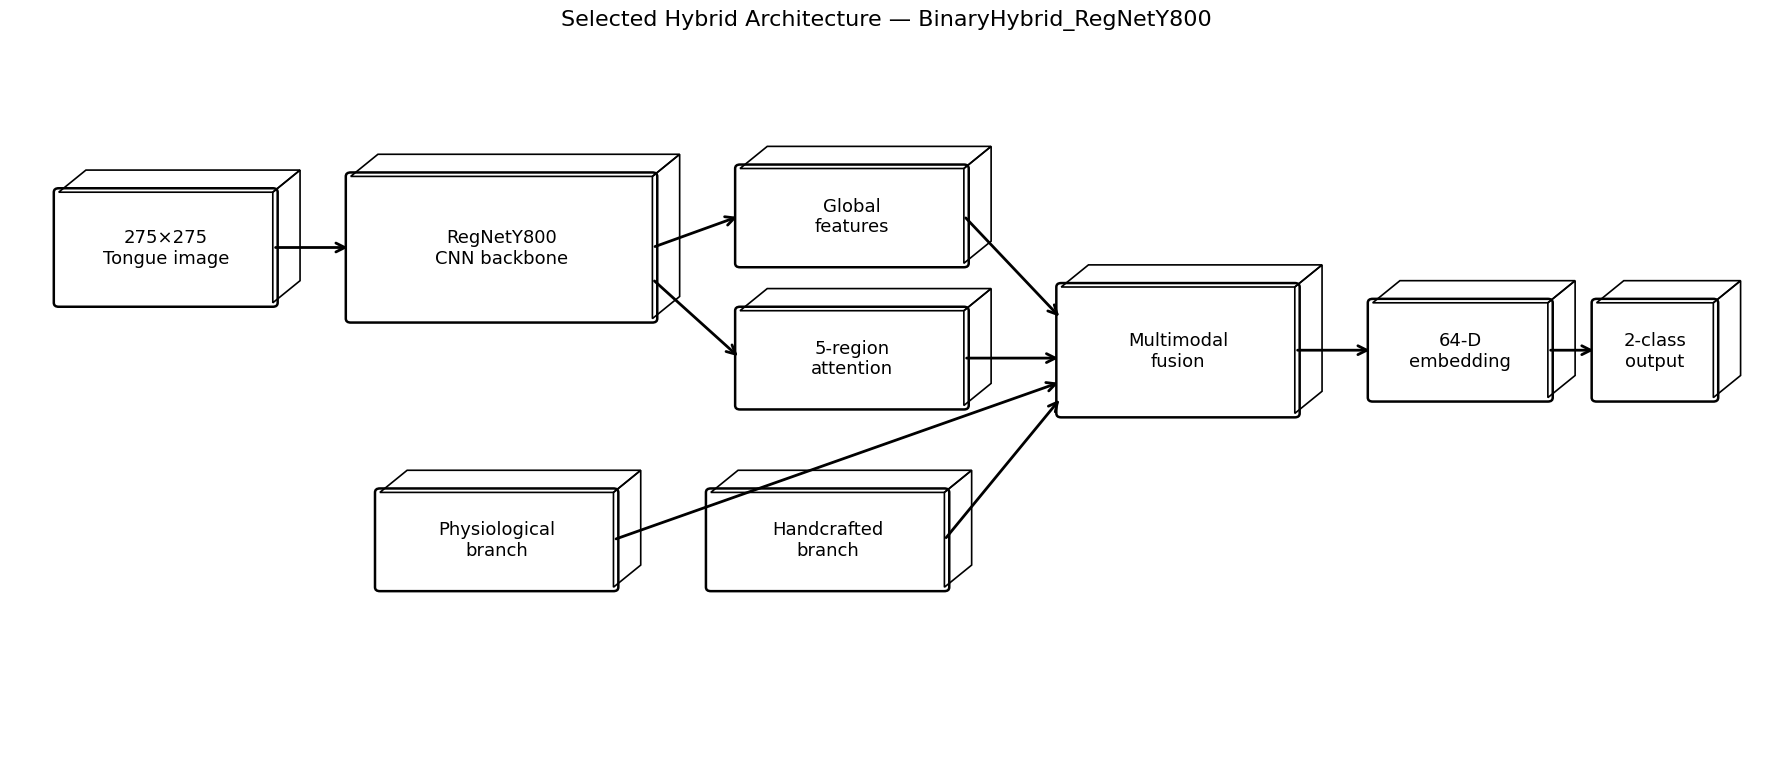

In [22]:
from matplotlib.patches import Polygon, FancyBboxPatch
fig,ax=plt.subplots(figsize=(18,8))
ax.set_xlim(0,18)
ax.set_ylim(0,9)
ax.axis("off")
def block3d(x,y,w,h,label,depth=.28):
    front=FancyBboxPatch(
        (x,y),w,h,
        boxstyle="round,pad=.05",
        facecolor="white",
        edgecolor="black",
        linewidth=1.8
    )
    ax.add_patch(front)

    side=Polygon([
        (x+w,y),
        (x+w+depth,y+depth),
        (x+w+depth,y+h+depth),
        (x+w,y+h)
    ],closed=True,fill=False,edgecolor="black",linewidth=1.2)

    top=Polygon([
        (x,y+h),
        (x+depth,y+h+depth),
        (x+w+depth,y+h+depth),
        (x+w,y+h)
    ],closed=True,fill=False,edgecolor="black",linewidth=1.2)

    ax.add_patch(side)
    ax.add_patch(top)
    ax.text(
        x+w/2,y+h/2,label,
        ha="center",va="center",
        fontsize=13
    )

def arrow(x1,y1,x2,y2):
    ax.annotate(
        "",
        xy=(x2,y2),
        xytext=(x1,y1),
        arrowprops=dict(arrowstyle="->",lw=2)
    )

block3d(.5,5.8,2.2,1.4,"275×275\nTongue image")
block3d(3.5,5.6,3.1,1.8,BEST_MODEL_NAME.replace("BinaryHybrid_","")+"\nCNN backbone")
block3d(7.5,6.3,2.3,1.2,"Global\nfeatures")
block3d(7.5,4.5,2.3,1.2,"5-region\nattention")
block3d(3.8,2.2,2.4,1.2,"Physiological\nbranch")
block3d(7.2,2.2,2.4,1.2,"Handcrafted\nbranch")
block3d(10.8,4.4,2.4,1.6,"Multimodal\nfusion")
block3d(14.0,4.6,1.8,1.2,"64-D\nembedding")
block3d(16.3,4.6,1.2,1.2,"2-class\noutput")

arrow(2.7,6.5,3.5,6.5)
arrow(6.6,6.5,7.5,6.9)
arrow(6.6,6.1,7.5,5.1)
arrow(9.8,6.9,10.8,5.6)
arrow(9.8,5.1,10.8,5.1)
arrow(6.2,2.8,10.8,4.8)
arrow(9.6,2.8,10.8,4.6)
arrow(13.2,5.2,14.0,5.2)
arrow(15.8,5.2,16.3,5.2)

ax.set_title(
    f"Selected Hybrid Architecture — {BEST_MODEL_NAME}",
    fontsize=16,
    pad=18
)
savefig("selected_model_3d_architecture")

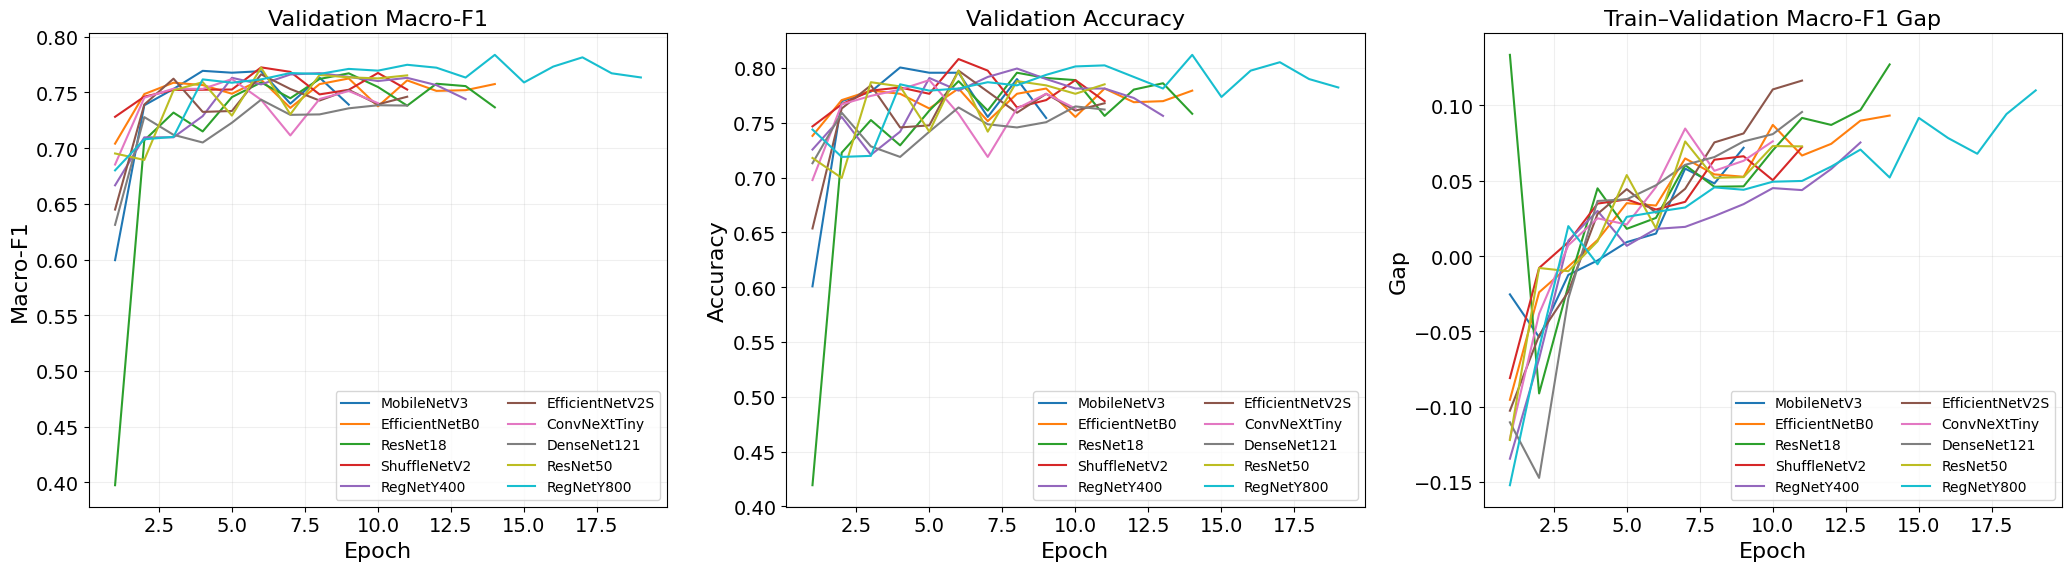

In [23]:
# TEN-MODEL LEARNING-CURVE COMPARISON
fig,ax=plt.subplots(1,3,figsize=(21,6))

for name in MODEL_NAMES:
    h=RUNS[name]["history"]
    short=name.replace("BinaryHybrid_","")

    ax[0].plot(
        h.epoch,h.val_macro_f1,
        label=short
    )
    ax[1].plot(
        h.epoch,h.val_accuracy,
        label=short
    )
    ax[2].plot(
        h.epoch,h.overfit_gap,
        label=short
    )

ax[0].set_title("Validation Macro-F1")
ax[1].set_title("Validation Accuracy")
ax[2].set_title("Train–Validation Macro-F1 Gap")

ax[0].set_ylabel("Macro-F1")
ax[1].set_ylabel("Accuracy")
ax[2].set_ylabel("Gap")

for a in ax:
    a.set_xlabel("Epoch")
    a.grid(alpha=.20)
    a.legend(fontsize=10,ncol=2)

savefig("ten_model_learning_curves")

In [24]:
# CELL 18 — TEST TEN SAVED MODELS
TEST_ROWS=[]; TEST_STORE={}; _,_,te=make_loaders(True)
for name in MODEL_NAMES:
    model=BinaryHybridNet(BACKBONE_MAP[name],PHYS.shape[1],HAND.shape[1]).to(DEVICE); model.load_state_dict(torch.load(RUNS[name]['checkpoint'],map_location=DEVICE)['model']); yt,pt,ids,att,emb=predict_loader(model,te,True); mm=binary_metrics(yt,pt); TEST_ROWS.append({'model':name,**mm}); TEST_STORE[name]={'y':yt,'probs':pt,'ids':ids,'attention':att,'embedding':emb}; del model; gc.collect();
    if torch.cuda.is_available(): torch.cuda.empty_cache()
TEST_TABLE=pd.DataFrame(TEST_ROWS); TEST_TABLE.to_csv(TABLE_DIR/'ten_binary_models_test.csv',index=False); display(TEST_TABLE.sort_values('macro_f1',ascending=False))

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,precision_class1,recall_sensitivity_class1,specificity_class0,f1_class1,npv_class0,false_positive_rate,false_negative_rate,youden_j,roc_auc,average_precision,kappa,mcc,brier_score,log_loss
8,BinaryHybrid_ResNet50,0.826923,0.817399,0.779538,0.817399,0.793195,0.639535,0.797101,0.837696,0.709677,0.919540,0.162304,0.202899,0.634798,0.892215,0.799265,0.588492,0.595735,0.123027,0.388974
0,BinaryHybrid_MobileNetV3,0.828846,0.811765,0.780580,0.811765,0.792755,0.648485,0.775362,0.848168,0.706271,0.912676,0.151832,0.224638,0.623530,0.887188,0.772989,0.586859,0.591524,0.121142,0.394291
3,BinaryHybrid_ShuffleNetV2,0.834615,0.797177,0.786902,0.797177,0.791713,0.678082,0.717391,0.876963,0.697183,0.895722,0.123037,0.282609,0.594355,0.890792,0.792936,0.583551,0.583989,0.117438,0.369636
4,BinaryHybrid_RegNetY400,0.823077,0.793953,0.772894,0.793953,0.781875,0.647436,0.731884,0.856021,0.687075,0.898352,0.143979,0.268116,0.587905,0.897185,0.798977,0.564394,0.566455,0.118265,0.369701
5,BinaryHybrid_EfficientNetV2S,0.815385,0.793345,0.764867,0.793345,0.776019,0.628049,0.746377,0.840314,0.682119,0.901685,0.159686,0.253623,0.586691,0.886865,0.777311,0.553392,0.557486,0.122597,0.381125
6,BinaryHybrid_ConvNeXtTiny,0.807692,0.795053,0.758355,0.795053,0.771062,0.609195,0.768116,0.821990,0.679487,0.907514,0.178010,0.231884,0.590105,0.879259,0.766014,0.544722,0.552190,0.131545,0.412691
2,BinaryHybrid_ResNet18,0.801923,0.800383,0.755506,0.800383,0.768730,0.594595,0.797101,0.803665,0.681115,0.916418,0.196335,0.202899,0.600766,0.891437,0.791922,0.541831,0.554075,0.126620,0.392360
7,BinaryHybrid_DenseNet121,0.794231,0.806719,0.753119,0.806719,0.765144,0.577889,0.833333,0.780105,0.682493,0.928349,0.219895,0.166667,0.613438,0.887567,0.796946,0.537551,0.557266,0.138540,0.425615
9,BinaryHybrid_RegNetY800,0.800000,0.762046,0.745086,0.762046,0.752399,0.610390,0.681159,0.842932,0.643836,0.879781,0.157068,0.318841,0.524091,0.887928,0.777336,0.505378,0.506848,0.124426,0.387937
1,BinaryHybrid_EfficientNetB0,0.767308,0.776823,0.726772,0.776823,0.736028,0.541872,0.797101,0.756545,0.645161,0.911672,0.243455,0.202899,0.553646,0.887093,0.789871,0.481252,0.501102,0.143482,0.423097


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,precision_class1,recall_sensitivity_class1,specificity_class0,f1_class1,npv_class0,false_positive_rate,false_negative_rate,youden_j,roc_auc,average_precision,kappa,mcc,brier_score,log_loss
0,0.8,0.762046,0.745086,0.762046,0.752399,0.61039,0.681159,0.842932,0.643836,0.879781,0.157068,0.318841,0.524091,0.887928,0.777336,0.505378,0.506848,0.124426,0.387937


,precision,recall,f1-score,support
Non-FLD,0.879781,0.842932,0.860963,382.0
Mild FLD,0.610390,0.681159,0.643836,138.0
accuracy,0.800000,0.800000,0.800000,0.8
macro avg,0.745086,0.762046,0.752399,520.0
weighted avg,0.808289,0.800000,0.803340,520.0


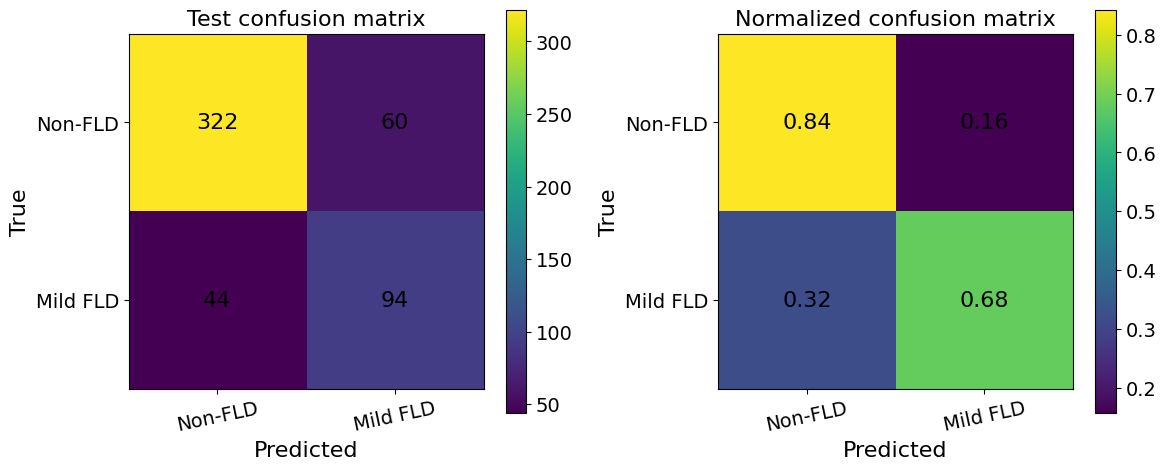

In [25]:
# CELL 19 — BEST MODEL EVALUATION / TABLES
best=TEST_STORE[BEST_MODEL_NAME]; yt,pt,test_ids=best['y'],best['probs'],best['ids']; pred=pt.argmax(1); BEST_METRICS=binary_metrics(yt,pt); pd.DataFrame([BEST_METRICS]).to_csv(TABLE_DIR/'best_binary_test_metrics.csv',index=False); display(pd.DataFrame([BEST_METRICS]))
report=pd.DataFrame(classification_report(yt,pred,target_names=CLASS_NAMES,output_dict=True,zero_division=0)).T; report.to_csv(TABLE_DIR/'best_binary_classification_report.csv'); display(report)
cm=confusion_matrix(yt,pred,labels=[0,1]); cmn=confusion_matrix(yt,pred,labels=[0,1],normalize='true'); fig,ax=plt.subplots(1,2,figsize=(12,5))
for a,m,title,fmt in [(ax[0],cm,'Test confusion matrix','d'),(ax[1],cmn,'Normalized confusion matrix','.2f')]:
    im=a.imshow(m); a.set_xticks([0,1],CLASS_NAMES,rotation=12); a.set_yticks([0,1],CLASS_NAMES); a.set_xlabel('Predicted'); a.set_ylabel('True'); a.set_title(title)
    for i in range(2):
        for j in range(2): a.text(j,i,format(m[i,j],fmt),ha='center',va='center')
    fig.colorbar(im,ax=a)
savefig('01_binary_confusion')

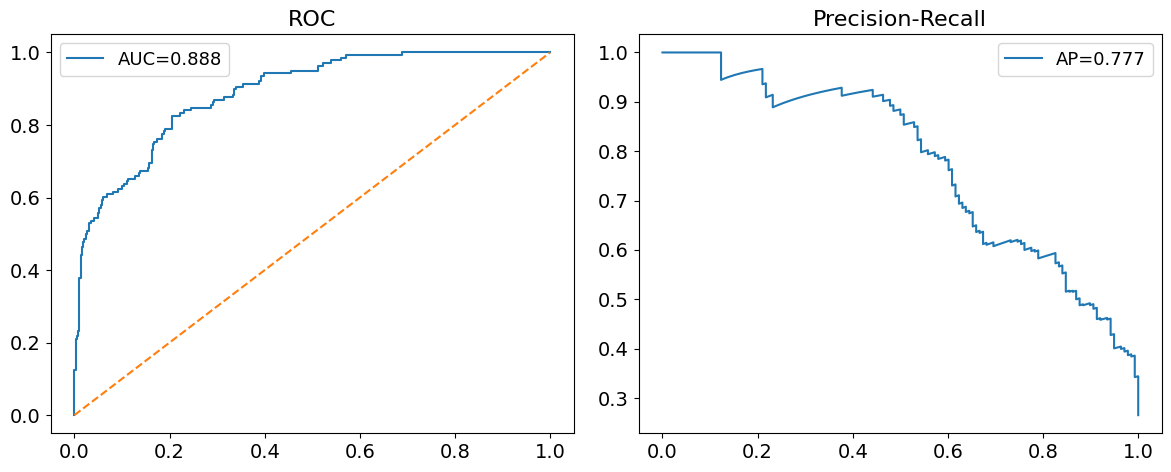

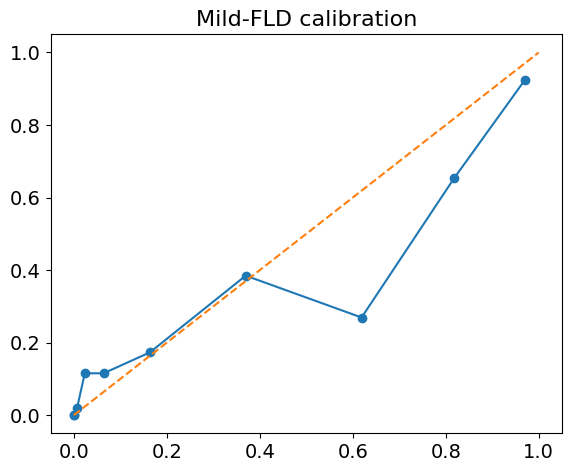

,metric,estimate,ci95_low,ci95_high
0,accuracy,0.800000,0.767260,0.834663
1,balanced_accuracy,0.762046,0.719667,0.805156
2,macro_f1,0.752399,0.710465,0.793911
3,roc_auc,0.887928,0.855640,0.915929
4,kappa,0.505378,0.421988,0.588533
5,mcc,0.506848,0.425630,0.591163


In [26]:
# CELL 20 — ROC / PR / CALIBRATION / BOOTSTRAP 95% CI
fpr,tpr,_=roc_curve(yt,pt[:,1]); precision,recall,_=precision_recall_curve(yt,pt[:,1]); fig,ax=plt.subplots(1,2,figsize=(12,5)); ax[0].plot(fpr,tpr,label=f"AUC={roc_auc_score(yt,pt[:,1]):.3f}"); ax[0].plot([0,1],[0,1],'--'); ax[0].legend(); ax[0].set_title('ROC'); ax[1].plot(recall,precision,label=f"AP={average_precision_score(yt,pt[:,1]):.3f}"); ax[1].legend(); ax[1].set_title('Precision-Recall'); savefig('02_binary_roc_pr')
frac,meanp=calibration_curve(yt,pt[:,1],n_bins=10,strategy='quantile'); plt.figure(figsize=(6,5)); plt.plot(meanp,frac,marker='o'); plt.plot([0,1],[0,1],'--'); plt.title('Mild-FLD calibration'); savefig('03_binary_calibration')
rng=np.random.default_rng(SEED); boot=[]
for _ in range(1000):
    ids=rng.choice(len(yt),len(yt),replace=True)
    if len(np.unique(yt[ids]))<2: continue
    m=binary_metrics(yt[ids],pt[ids]); boot.append({k:m[k] for k in ['accuracy','balanced_accuracy','macro_f1','roc_auc','kappa','mcc']})
boot=pd.DataFrame(boot); ci=pd.DataFrame({'metric':boot.columns,'estimate':[BEST_METRICS[c] for c in boot.columns],'ci95_low':[boot[c].quantile(.025) for c in boot.columns],'ci95_high':[boot[c].quantile(.975) for c in boot.columns]}); ci.to_csv(TABLE_DIR/'binary_bootstrap_95ci.csv',index=False); display(ci)

,model,best_epoch,overfit_gap,val_accuracy,val_balanced_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_precision_class1,val_recall_sensitivity_class1,...,npv_class0,false_positive_rate,false_negative_rate,youden_j,roc_auc,average_precision,kappa,mcc,brier_score,log_loss
0,BinaryHybrid_RegNetY800,14,0.052156,0.811900,0.787105,0.780773,0.787105,0.783741,0.691176,0.720859,...,0.879781,0.157068,0.318841,0.524091,0.887928,0.777336,0.505378,0.506848,0.124426,0.387937
1,BinaryHybrid_ShuffleNetV2,6,0.030888,0.808061,0.767604,0.778415,0.767604,0.772494,0.707237,0.659509,...,0.895722,0.123037,0.282609,0.594355,0.890792,0.792936,0.583551,0.583989,0.117438,0.369636
2,BinaryHybrid_ResNet50,6,0.018403,0.797505,0.782478,0.765506,0.782478,0.772248,0.655827,0.742331,...,0.919540,0.162304,0.202899,0.634798,0.892215,0.799265,0.588492,0.595735,0.123027,0.388974
3,BinaryHybrid_MobileNetV3,4,-0.002975,0.800384,0.771207,0.767702,0.771207,0.769391,0.676647,0.693252,...,0.912676,0.151832,0.224638,0.623530,0.887188,0.772989,0.586859,0.591524,0.121142,0.394291
4,BinaryHybrid_RegNetY400,8,0.026531,0.799424,0.768002,0.766676,0.768002,0.767330,0.677812,0.684049,...,0.898352,0.143979,0.268116,0.587905,0.897185,0.798977,0.564394,0.566455,0.118265,0.369701
5,BinaryHybrid_ResNet18,9,0.046288,0.790787,0.780932,0.759522,0.780932,0.767148,0.640625,0.754601,...,0.916418,0.196335,0.202899,0.600766,0.891437,0.791922,0.541831,0.554075,0.126620,0.392360
6,BinaryHybrid_EfficientNetV2S,6,0.028740,0.797505,0.768276,0.764392,0.768276,0.766254,0.671642,0.690184,...,0.901685,0.159686,0.253623,0.586691,0.886865,0.777311,0.553392,0.557486,0.122597,0.381125
7,BinaryHybrid_EfficientNetB0,9,0.052642,0.781190,0.786480,0.755194,0.786480,0.762543,0.615566,0.800613,...,0.911672,0.243455,0.202899,0.553646,0.887093,0.789871,0.481252,0.501102,0.143482,0.423097
8,BinaryHybrid_ConvNeXtTiny,5,0.020923,0.788868,0.771181,0.755836,0.771181,0.762017,0.644809,0.723926,...,0.907514,0.178010,0.231884,0.590105,0.879259,0.766014,0.544722,0.552190,0.131545,0.412691
9,BinaryHybrid_DenseNet121,6,0.046972,0.763916,0.765556,0.736909,0.765556,0.743496,0.594787,0.769939,...,0.928349,0.219895,0.166667,0.613438,0.887567,0.796946,0.537551,0.557266,0.138540,0.425615


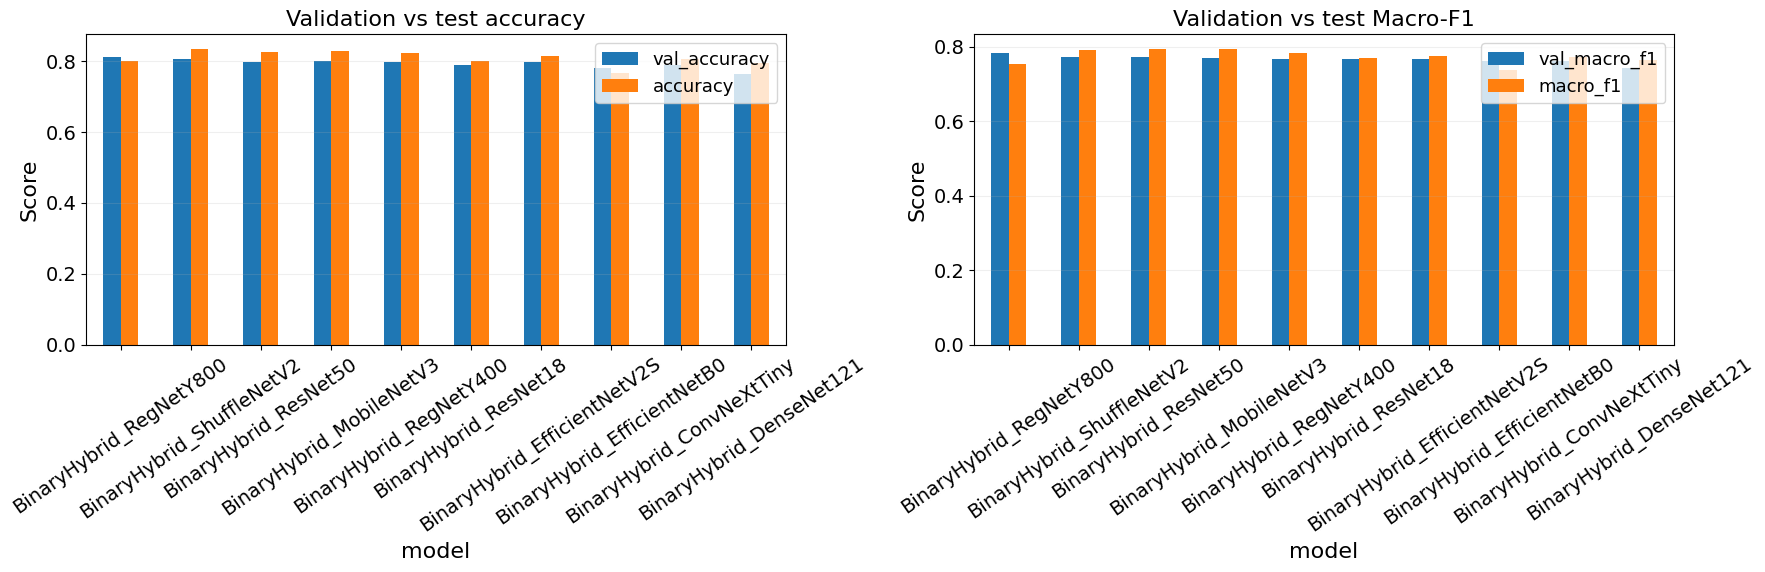

In [27]:
# CELL 21 — TEN-MODEL COMPLETE COMPARISON
combined=VAL_TABLE.merge(
    TEST_TABLE,
    on="model",
    how="left"
)

combined.to_csv(
    TABLE_DIR/"ten_binary_complete_comparison.csv",
    index=False
)

display(combined)

fig,ax=plt.subplots(1,2,figsize=(18,6))

combined.set_index("model")[
    ["val_accuracy","accuracy"]
].plot(kind="bar",ax=ax[0])

combined.set_index("model")[
    ["val_macro_f1","macro_f1"]
].plot(kind="bar",ax=ax[1])

ax[0].set_title("Validation vs test accuracy")
ax[1].set_title("Validation vs test Macro-F1")

for a in ax:
    a.set_ylabel("Score")
    a.tick_params(axis="x",rotation=35)
    a.grid(axis="y",alpha=.20)

savefig("04_ten_model_comparison")

In [28]:
# STATISTICAL MODEL COMPARISON — BOOTSTRAP CIs + EXACT McNEMAR
rng=np.random.default_rng(SEED+123)
ci_rows=[]

for name in MODEL_NAMES:
    store=TEST_STORE[name]
    yy=store["y"]
    pp=store["probs"]
    boots=[]

    for _ in range(500):
        ids=rng.choice(len(yy),len(yy),replace=True)

        if len(np.unique(yy[ids]))<2:
            continue

        mm=binary_metrics(
            yy[ids],
            pp[ids]
        )

        boots.append([
            mm["accuracy"],
            mm["macro_f1"],
            mm["roc_auc"],
            mm["mcc"]
        ])

    b=np.asarray(boots)

    for j,metric in enumerate(
        ["accuracy","macro_f1","roc_auc","mcc"]
    ):
        ci_rows.append({
            "model":name,
            "metric":metric,
            "estimate":binary_metrics(yy,pp)[metric],
            "ci95_low":float(np.quantile(b[:,j],.025)),
            "ci95_high":float(np.quantile(b[:,j],.975))
        })

BOOTSTRAP_ALL=pd.DataFrame(ci_rows)
BOOTSTRAP_ALL.to_csv(
    TABLE_DIR/"ten_model_bootstrap_95CI.csv",
    index=False
)

best_store=TEST_STORE[BEST_MODEL_NAME]
best_true=best_store["y"]
best_pred=best_store["probs"].argmax(1)

mcnemar_rows=[]

for name in MODEL_NAMES:
    if name==BEST_MODEL_NAME:
        continue

    other=TEST_STORE[name]["probs"].argmax(1)

    best_ok=(best_pred==best_true)
    other_ok=(other==best_true)

    n10=int(np.sum(best_ok & ~other_ok))
    n01=int(np.sum(~best_ok & other_ok))
    discordant=n10+n01

    if discordant:
        pvalue=float(
            stats.binomtest(
                n10,
                n=discordant,
                p=.5,
                alternative="two-sided"
            ).pvalue
        )
    else:
        pvalue=1.0

    mcnemar_rows.append({
        "validation_selected_model":BEST_MODEL_NAME,
        "comparison_model":name,
        "best_correct_other_wrong":n10,
        "best_wrong_other_correct":n01,
        "discordant_pairs":discordant,
        "exact_mcnemar_p":pvalue
    })

MCNEMAR_TABLE=pd.DataFrame(mcnemar_rows)
MCNEMAR_TABLE.to_csv(
    TABLE_DIR/"mcnemar_selected_vs_other_models.csv",
    index=False
)

display(
    BOOTSTRAP_ALL[
        BOOTSTRAP_ALL.metric=="accuracy"
    ].sort_values("estimate",ascending=False)
)
display(MCNEMAR_TABLE)

,model,metric,estimate,ci95_low,ci95_high
12,BinaryHybrid_ShuffleNetV2,accuracy,0.834615,0.801923,0.862548
0,BinaryHybrid_MobileNetV3,accuracy,0.828846,0.796154,0.859615
32,BinaryHybrid_ResNet50,accuracy,0.826923,0.794231,0.857692
16,BinaryHybrid_RegNetY400,accuracy,0.823077,0.790385,0.857692
20,BinaryHybrid_EfficientNetV2S,accuracy,0.815385,0.782692,0.846154
24,BinaryHybrid_ConvNeXtTiny,accuracy,0.807692,0.772067,0.840385
8,BinaryHybrid_ResNet18,accuracy,0.801923,0.771154,0.831779
36,BinaryHybrid_RegNetY800,accuracy,0.800000,0.764375,0.834615
28,BinaryHybrid_DenseNet121,accuracy,0.794231,0.757692,0.826923
4,BinaryHybrid_EfficientNetB0,accuracy,0.767308,0.730769,0.804856


,validation_selected_model,comparison_model,best_correct_other_wrong,best_wrong_other_correct,discordant_pairs,exact_mcnemar_p
0,BinaryHybrid_RegNetY800,BinaryHybrid_MobileNetV3,27,42,69,0.091186
1,BinaryHybrid_RegNetY800,BinaryHybrid_EfficientNetB0,48,31,79,0.071163
2,BinaryHybrid_RegNetY800,BinaryHybrid_ResNet18,34,35,69,1.000000
3,BinaryHybrid_RegNetY800,BinaryHybrid_ShuffleNetV2,21,39,60,0.027340
4,BinaryHybrid_RegNetY800,BinaryHybrid_RegNetY400,23,35,58,0.148006
5,BinaryHybrid_RegNetY800,BinaryHybrid_EfficientNetV2S,28,36,64,0.381733
6,BinaryHybrid_RegNetY800,BinaryHybrid_ConvNeXtTiny,31,35,66,0.712231
7,BinaryHybrid_RegNetY800,BinaryHybrid_DenseNet121,37,34,71,0.812589
8,BinaryHybrid_RegNetY800,BinaryHybrid_ResNet50,21,35,56,0.081427


,silhouette,ARI_vs_class,NMI_vs_class
0,0.562409,-0.020444,0.175133


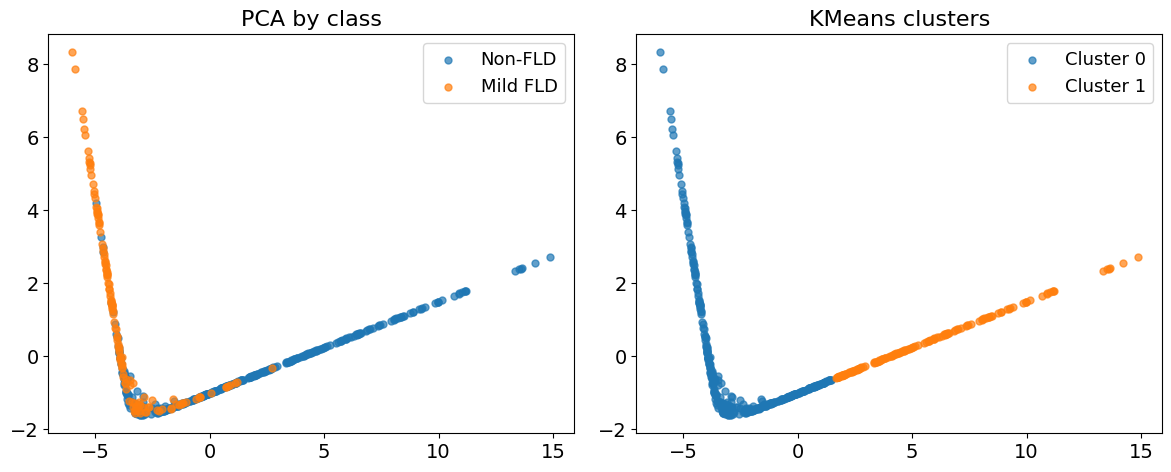

In [ ]:
# CELL 22 — CLUSTERING
embedding=best['embedding']; z2=PCA(n_components=2,random_state=SEED).fit_transform(embedding); clusters=KMeans(n_clusters=2,random_state=SEED,n_init=20).fit_predict(embedding); cmets={'silhouette':float(silhouette_score(embedding,clusters)) if len(np.unique(clusters))>1 else np.nan,'ARI_vs_class':float(adjusted_rand_score(yt,clusters)),'NMI_vs_class':float(normalized_mutual_info_score(yt,clusters))}; pd.DataFrame([cmets]).to_csv(TABLE_DIR/'binary_clustering_metrics.csv',index=False); display(pd.DataFrame([cmets])); fig,ax=plt.subplots(1,2,figsize=(12,5))
for c,n in enumerate(CLASS_NAMES):
    m=yt==c; ax[0].scatter(z2[m,0],z2[m,1],s=25,alpha=.7,label=n)
for c in range(2):
    m=clusters==c; ax[1].scatter(z2[m,0],z2[m,1],s=25,alpha=.7,label=f'Cluster {c}')
ax[0].legend(); ax[1].legend(); ax[0].set_title('PCA by class'); ax[1].set_title('KMeans clusters'); savefig('05_binary_clustering')

In [38]:
# CELL 23 — LOAD BEST MODEL FOR XAI
BEST_MODEL=BinaryHybridNet(BACKBONE_MAP[BEST_MODEL_NAME],PHYS.shape[1],HAND.shape[1]).to(DEVICE); BEST_MODEL.load_state_dict(torch.load(RUNS[BEST_MODEL_NAME]['checkpoint'],map_location=DEVICE)['model']); BEST_MODEL.eval()
class XAIWrapper(nn.Module):
    def __init__(self,model,phys,hand): super().__init__(); self.model=model; self.register_buffer('phys',phys.reshape(1,-1)); self.register_buffer('hand',hand.reshape(1,-1))
    def forward(self,x): return self.model(x,self.phys.expand(x.shape[0],-1),self.hand.expand(x.shape[0],-1))[0]
def norm_map(a):
    a=np.nan_to_num(np.abs(a).astype(np.float32)); a-=a.min(); a/=a.max()+1e-8; return a

In [39]:
# CELL 24 — GRAD-CAM / GRAD-CAM++ / IG / GRADIENTSHAP
def gradient_xai(row_idx,target):
    p=torch.tensor(PHYS[row_idx],dtype=torch.float32,device=DEVICE); h=torch.tensor(HAND[row_idx],dtype=torch.float32,device=DEVICE); wrapper=XAIWrapper(BEST_MODEL,p,h).to(DEVICE).eval(); x=EVAL_TF(Image.fromarray(get_raw(row_idx))).unsqueeze(0).to(DEVICE); layer=[BEST_MODEL.backbone.target_layer]
    gc=GradCAM(model=wrapper,target_layers=layer)(input_tensor=x,targets=[ClassifierOutputTarget(target)])[0]; gcpp=GradCAMPlusPlus(model=wrapper,target_layers=layer)(input_tensor=x,targets=[ClassifierOutputTarget(target)])[0]; ig=IntegratedGradients(wrapper).attribute(x,baselines=torch.zeros_like(x),target=target,n_steps=24); gs=GradientShap(wrapper).attribute(x,baselines=torch.cat([torch.zeros_like(x),torch.randn_like(x)*.03],0),target=target,n_samples=20,stdevs=.02)
    return norm_map(gc),norm_map(gcpp),norm_map(ig.abs().sum(1)[0].detach().cpu().numpy()),norm_map(gs.abs().sum(1)[0].detach().cpu().numpy())

In [40]:
# CELL 25 — KERNELSHAP / LIME
SUPERPIXELS=20; KERNEL_SHAP_NSAMPLES=100; LIME_NUM_SAMPLES=350

def fixed_predict(row_idx,images):
    p=torch.tensor(PHYS[row_idx],dtype=torch.float32,device=DEVICE).reshape(1,-1)
    h=torch.tensor(HAND[row_idx],dtype=torch.float32,device=DEVICE).reshape(1,-1)
    xs=[]
    for im in images:
        arr=np.asarray(im)
        if arr.max()<=1.5: arr=(arr*255).astype(np.uint8)
        else: arr=np.clip(arr,0,255).astype(np.uint8)
        xs.append(EVAL_TF(Image.fromarray(arr)))
    xb=torch.stack(xs).to(DEVICE)
    with torch.no_grad():
        z=BEST_MODEL(xb,p.expand(len(xs),-1),h.expand(len(xs),-1))[0]
        return torch.softmax(z,1).cpu().numpy()

def kernel_shap_map(row_idx,target):
    rgb=get_raw(row_idx).astype(np.float32)/255
    seg=slic(rgb,n_segments=SUPERPIXELS,compactness=10,start_label=0,channel_axis=-1)
    K=int(seg.max()+1); base=cv2.GaussianBlur(rgb,(31,31),0)
    def f(z):
        ims=[]
        for coalition in np.asarray(z):
            im=base.copy()
            for s,on in enumerate(coalition):
                if on>.5: im[seg==s]=rgb[seg==s]
            ims.append(im)
        return fixed_predict(row_idx,ims)[:,target]
    explanation=shap.KernelExplainer(
        f,np.zeros((1,K),dtype=np.float32)
    ).shap_values(
        np.ones((1,K),dtype=np.float32),
        nsamples=KERNEL_SHAP_NSAMPLES
    )

    if isinstance(explanation,list):
        explanation=explanation[0]

    sv=np.asarray(explanation,dtype=np.float32).squeeze()
    if sv.size!=K:
        sv=sv.reshape(-1)[:K]

    if sv.size<K:
        sv=np.pad(sv,(0,K-sv.size))
    amap=np.zeros(seg.shape,dtype=np.float32)
    for s in range(K): amap[seg==s]=abs(float(sv[s]))
    return norm_map(amap)

def lime_map(row_idx,target):
    rgb=get_raw(row_idx)
    segfun=lambda im:slic(im,n_segments=SUPERPIXELS,compactness=10,start_label=0,channel_axis=-1)
    explainer=lime_image.LimeImageExplainer(random_state=SEED)
    try:
        exp=explainer.explain_instance(
            rgb,lambda imgs:fixed_predict(row_idx,imgs),
            labels=[target],num_samples=LIME_NUM_SAMPLES,
            segmentation_fn=segfun,hide_color=0,progress_bar=False
        )
    except TypeError:
        # Compatibility with LIME versions that do not expose progress_bar.
        exp=explainer.explain_instance(
            rgb,lambda imgs:fixed_predict(row_idx,imgs),
            labels=[target],num_samples=LIME_NUM_SAMPLES,
            segmentation_fn=segfun,hide_color=0
        )
    amap=np.zeros(exp.segments.shape,dtype=np.float32)
    for s,w in exp.local_exp[target]: amap[exp.segments==s]=abs(float(w))
    return norm_map(amap)

In [41]:
# CELL 26 — QUANTITATIVE XAI
def integrate_curve(y,x): return float(np.trapezoid(y,x)) if hasattr(np,'trapezoid') else float(np.trapz(y,x))
def target_probability(row_idx,target,x):
    p=torch.tensor(PHYS[row_idx],dtype=torch.float32,device=DEVICE).reshape(1,-1); h=torch.tensor(HAND[row_idx],dtype=torch.float32,device=DEVICE).reshape(1,-1)
    with torch.no_grad(): logits,_,_=BEST_MODEL(x,p,h); return float(torch.softmax(logits,1)[0,target].cpu())
def xai_quant(row_idx,target,sal):
    rgb=get_raw(row_idx)
    mask=get_mask(row_idx).astype(bool)
    if sal.shape!=mask.shape:
        sal=cv2.resize(
            np.asarray(sal,dtype=np.float32),
            (mask.shape[1],mask.shape[0]),
            interpolation=cv2.INTER_LINEAR
        )
    vals=sal[mask]; thr=np.quantile(vals,.85) if len(vals) else 1.; top=(sal>=thr)&mask; x=EVAL_TF(Image.fromarray(rgb)).unsqueeze(0).to(DEVICE); orig=target_probability(row_idx,target,x); mt=torch.from_numpy(top).to(DEVICE); xd=x.clone(); xd[0,:,mt]=0; xi=torch.zeros_like(x); xi[0,:,mt]=x[0,:,mt]; coords=np.argwhere(mask); order=np.argsort(-sal[mask]); fracs=np.linspace(0,1,11); dc=[]; ic=[]
    for f in fracs:
        n=int(len(order)*f); sel=coords[order[:n]]; d=x.clone(); ins=torch.zeros_like(x)
        if n:
            yy=torch.tensor(sel[:,0],device=DEVICE); xx=torch.tensor(sel[:,1],device=DEVICE); d[0,:,yy,xx]=0; ins[0,:,yy,xx]=x[0,:,yy,xx]
        dc.append(target_probability(row_idx,target,d)); ic.append(target_probability(row_idx,target,ins))
    return {'foreground_ratio':float(sal[mask].sum()/(sal.sum()+1e-8)),'comprehensiveness':orig-target_probability(row_idx,target,xd),'sufficiency':orig-target_probability(row_idx,target,xi),'deletion_auc':integrate_curve(dc,fracs),'insertion_auc':integrate_curve(ic,fracs)},top

In [42]:
# CELL 27 — RUN SIX XAI METHODS ON TEST IMAGES
chosen=[]
for c in range(2):
    loc=np.where((yt==c)&(pred==c))[0]
    if len(loc):
        chosen.append(int(test_ids[loc[np.argmax(pt[loc,c])]]))

wrong=np.where(pred!=yt)[0]
if len(wrong):
    chosen.append(int(test_ids[wrong[np.argmax(pt[wrong].max(1))]]))

chosen=list(dict.fromkeys(chosen))
METHODS=["Grad-CAM","Grad-CAM++","Integrated Gradients","GradientSHAP","KernelSHAP","LIME"]
rows=[]; agreements=[]; xai_errors=[]

def safe_map(name,fn,row_idx,target):
    try:
        sal=fn()
        sal=np.asarray(sal,dtype=np.float32)
        if sal.shape!=(IMG_SIZE,IMG_SIZE):
            sal=cv2.resize(sal,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_LINEAR)
        sal=norm_map(sal)
        return sal
    except Exception as e:
        xai_errors.append({
            "row_index":row_idx,
            "method":name,
            "error_type":type(e).__name__,
            "error":str(e)
        })
        print(f"XAI warning — {name} failed on row {row_idx}: {type(e).__name__}: {e}")
        return np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.float32)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/350 [00:00<?, ?it/s]

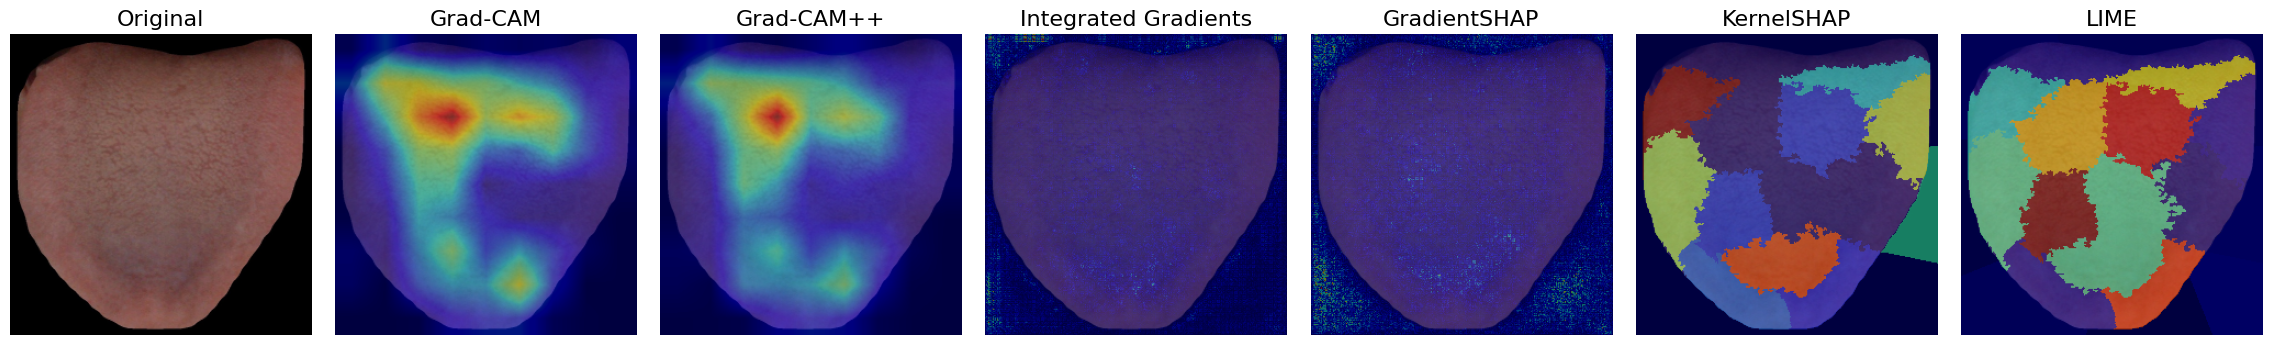

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/350 [00:00<?, ?it/s]

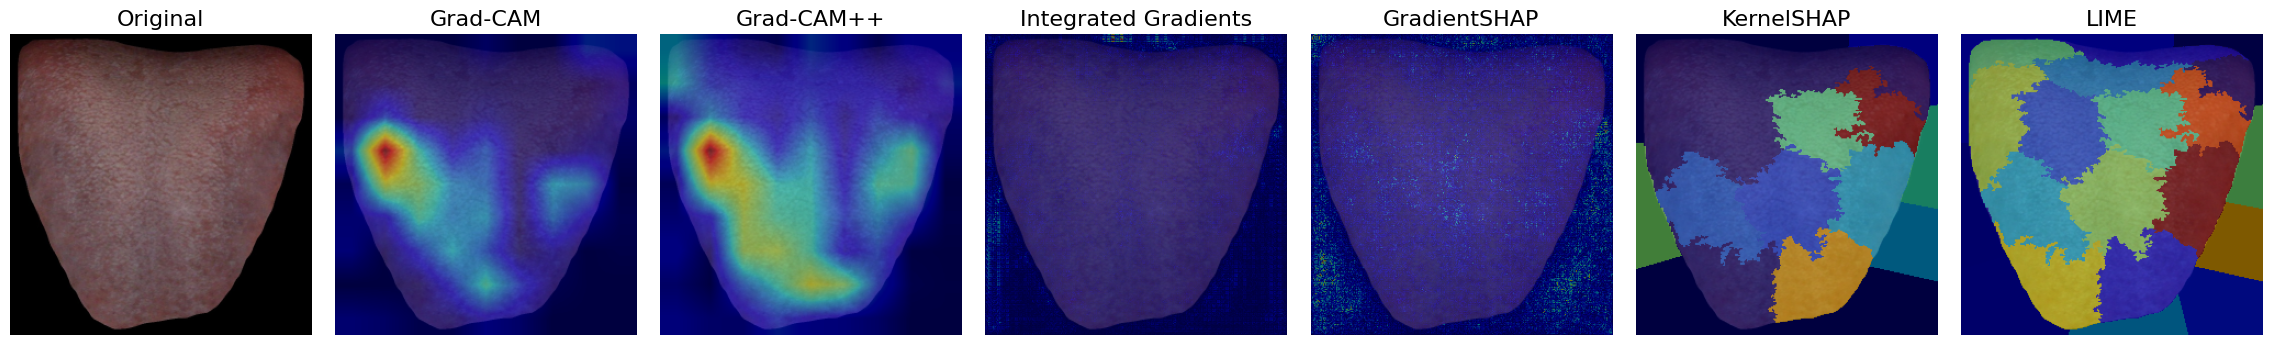

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/350 [00:00<?, ?it/s]

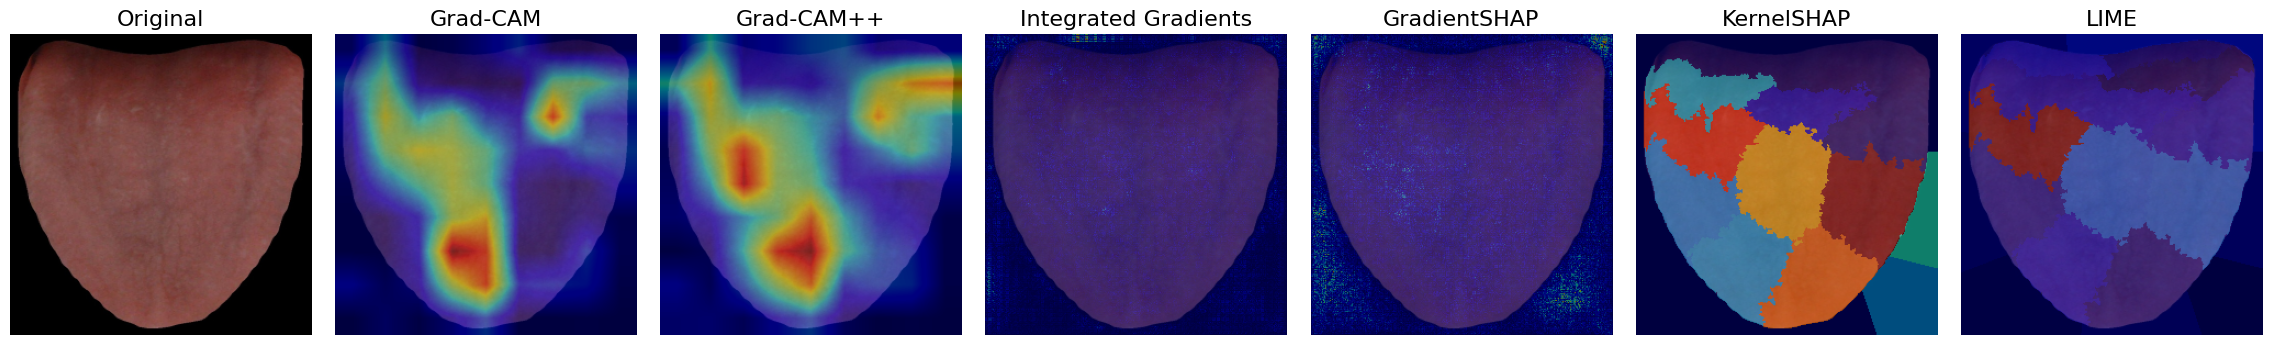

,foreground_ratio,comprehensiveness,sufficiency,deletion_auc,insertion_auc,row_index
method,,,,,,
Grad-CAM,0.922640,0.013738,0.009511,0.974807,0.992725,3684.0
Grad-CAM++,0.916001,0.008342,0.009990,0.977419,0.992264,3684.0
GradientSHAP,0.535211,0.027143,0.017934,0.969724,0.986077,3684.0
Integrated Gradients,0.551687,0.015835,0.016163,0.970982,0.983604,3684.0
KernelSHAP,0.891391,0.000516,0.002237,0.991810,0.994513,3684.0
LIME,0.906548,0.000613,0.001096,0.991629,0.995387,3684.0


In [43]:
# CONTINUATION — EXECUTE XAI ON SELECTED TEST IMAGES
for row_idx in chosen:
    pos=int(np.where(test_ids==row_idx)[0][0])
    target=int(pred[pos])

    # Compute gradient family once, but isolate failures.
    try:
        gc,gcpp,ig,gs=gradient_xai(row_idx,target)
    except Exception as e:
        print("Gradient-family XAI warning:",type(e).__name__,e)
        gc=gcpp=ig=gs=np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.float32)
        for name in ["Grad-CAM","Grad-CAM++","Integrated Gradients","GradientSHAP"]:
            xai_errors.append({"row_index":row_idx,"method":name,"error_type":type(e).__name__,"error":str(e)})

    ks=safe_map("KernelSHAP",lambda:kernel_shap_map(row_idx,target),row_idx,target)
    lm=safe_map("LIME",lambda:lime_map(row_idx,target),row_idx,target)

    maps={
        "Grad-CAM":norm_map(gc),
        "Grad-CAM++":norm_map(gcpp),
        "Integrated Gradients":norm_map(ig),
        "GradientSHAP":norm_map(gs),
        "KernelSHAP":ks,
        "LIME":lm,
    }

    fig,ax=plt.subplots(1,7,figsize=(23,4))
    ax[0].imshow(get_raw(row_idx))
    ax[0].set_title("Original",fontsize=16)

    masks={}
    for j,(name,sal) in enumerate(maps.items(),1):
        ax[j].imshow(get_raw(row_idx))
        ax[j].imshow(sal,cmap="jet",alpha=.5)
        ax[j].set_title(name,fontsize=16)

        try:
            met,top=xai_quant(row_idx,target,sal)
        except Exception as e:
            print(f"Quant-XAI warning — {name}: {e}")
            met={
                "foreground_ratio":np.nan,
                "comprehensiveness":np.nan,
                "sufficiency":np.nan,
                "deletion_auc":np.nan,
                "insertion_auc":np.nan,
            }
            top=np.zeros((IMG_SIZE,IMG_SIZE),dtype=bool)

        met.update({
            "row_index":row_idx,
            "method":name,
            "true_class":CLASS_NAMES[int(yt[pos])],
            "predicted_class":CLASS_NAMES[target],
        })
        rows.append(met)
        masks[name]=top

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.savefig(XAI_DIR/f"xai_{row_idx}.png",dpi=400,bbox_inches="tight"); plt.savefig(XAI_DIR/f"xai_{row_idx}.pdf",bbox_inches="tight")
    plt.show()

    for a_i in range(len(METHODS)):
        for b_i in range(a_i+1,len(METHODS)):
            ma=masks[METHODS[a_i]]
            mb=masks[METHODS[b_i]]
            denom=ma.sum()+mb.sum()
            dice=(2*(ma&mb).sum()/denom) if denom else np.nan
            agreements.append({
                "row_index":row_idx,
                "a":METHODS[a_i],
                "b":METHODS[b_i],
                "dice":dice
            })

XAI_RESULTS=pd.DataFrame(rows)
XAI_AGREE=pd.DataFrame(agreements)
XAI_ERRORS=pd.DataFrame(xai_errors)

XAI_RESULTS.to_csv(TABLE_DIR/"xai_quantitative.csv",index=False)
XAI_AGREE.to_csv(TABLE_DIR/"xai_agreement.csv",index=False)
XAI_ERRORS.to_csv(TABLE_DIR/"xai_runtime_warnings.csv",index=False)

if not XAI_RESULTS.empty:
    display(XAI_RESULTS.groupby("method").mean(numeric_only=True))
if len(XAI_ERRORS):
    display(XAI_ERRORS)

In [ ]:
# CELL 29 — ABLATIONS
ABLATIONS=[
 {'name':'Full_Raw_Balanced','balanced':True,'phys':True,'hand':True,'region':True},
 {'name':'Imbalanced_Raw','balanced':False,'phys':True,'hand':True,'region':True},
 {'name':'No_Region_Attention','balanced':True,'phys':True,'hand':True,'region':False},
 {'name':'No_Physiological','balanced':True,'phys':False,'hand':True,'region':True},
 {'name':'No_Handcrafted','balanced':True,'phys':True,'hand':False,'region':True},
]
display(pd.DataFrame(ABLATIONS))

,name,balanced,phys,hand,region
0,Full_Raw_Balanced,True,True,True,True
1,Imbalanced_Raw,False,True,True,True
2,No_Region_Attention,True,True,True,False
3,No_Physiological,True,False,True,True
4,No_Handcrafted,True,True,False,True


In [45]:
# CELL 30 — RUN ABLATIONS

ABL_ROWS = []
ABL_RUNS = {}

ABLATION_EPOCHS = 12
ABLATION_PATIENCE = 4

for a in ABLATIONS:

    tag = "ABL_" + a["name"]
    print("\n" + "=" * 20 + tag + "=" * 20)

    model, ckpt, hist, state, te = train_model(
        BEST_MODEL_NAME,
        balanced=a["balanced"],
        use_region=a["region"],
        use_phys=a["phys"],
        use_hand=a["hand"],
        epochs=ABLATION_EPOCHS,
        patience=ABLATION_PATIENCE,
        tag=tag
    )

    yy, pp, _, _, _ = predict_loader(
        model,
        te
    )

    tm = binary_metrics(
        yy,
        pp
    )

    br = hist.loc[
        hist.val_macro_f1.idxmax()
    ]

    ABL_ROWS.append({
        **a,

        "best_epoch": int(
            state["epoch"]
        ),

        "val_accuracy": float(
            state["val_metrics"]["accuracy"]
        ),

        "val_balanced_accuracy": float(
            state["val_metrics"]["balanced_accuracy"]
        ),

        "val_macro_precision": float(
            state["val_metrics"]["macro_precision"]
        ),

        "val_macro_recall": float(
            state["val_metrics"]["macro_recall"]
        ),

        "val_macro_f1": float(
            state["val_metrics"]["macro_f1"]
        ),

        "val_auc": float(
            state["val_metrics"]["roc_auc"]
        ),

        "val_mcc": float(
            state["val_metrics"]["mcc"]
        ),

        "val_kappa": float(
            state["val_metrics"]["kappa"]
        ),

        "overfit_gap": float(
            br["overfit_gap"]
        ),

        "test_accuracy": float(
            tm["accuracy"]
        ),

        "test_balanced_accuracy": float(
            tm["balanced_accuracy"]
        ),

        "test_macro_precision": float(
            tm["macro_precision"]
        ),

        "test_macro_recall": float(
            tm["macro_recall"]
        ),

        "test_macro_f1": float(
            tm["macro_f1"]
        ),

        "test_auc": float(
            tm["roc_auc"]
        ),

        "test_kappa": float(
            tm["kappa"]
        ),

        "test_mcc": float(
            tm["mcc"]
        ),

        "test_specificity": float(
            tm["specificity_class0"]
        ),

        "test_sensitivity": float(
            tm["recall_sensitivity_class1"]
        )
    })

    ABL_RUNS[a["name"]] = {
        "checkpoint": ckpt,
        "history": hist
    }

    # -------------------------------------------------
    # Clean GPU / RAM safely
    # -------------------------------------------------
    del model
    del yy
    del pp
    del tm

    # Important:
    # scipy.stats may have been overwritten earlier by a NumPy variable.
    # So re-import the real Python garbage-collector module here.
    import gc as garbage_collector

    garbage_collector.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ---------------------------------------------------------
# Create final ablation table
# ---------------------------------------------------------
ABL_TABLE = pd.DataFrame(
    ABL_ROWS
).sort_values(
    [
        "val_macro_f1",
        "val_auc",
        "val_mcc"
    ],
    ascending=[
        False,
        False,
        False
    ]
).reset_index(
    drop=True
)

ABL_TABLE["rank"] = np.arange(
    1,
    len(ABL_TABLE) + 1
)

ABL_TABLE.to_csv(
    TABLE_DIR / "binary_ablation_results.csv",
    index=False
)

display(
    ABL_TABLE
)

# ---------------------------------------------------------
# Best ablation selected using validation only
# ---------------------------------------------------------
BEST_ABLATION = ABL_TABLE.iloc[0].to_dict()

print("\n" + "=" * 70)
print("BEST ABLATION CONFIGURATION")
print("=" * 70)

print(
    "Name:",
    BEST_ABLATION["name"]
)

print(
    "Validation Accuracy:",
    f"{BEST_ABLATION['val_accuracy']:.4f}"
)

print(
    "Validation Macro-F1:",
    f"{BEST_ABLATION['val_macro_f1']:.4f}"
)

print(
    "Validation AUC:",
    f"{BEST_ABLATION['val_auc']:.4f}"
)

print(
    "Validation MCC:",
    f"{BEST_ABLATION['val_mcc']:.4f}"
)

print(
    "Overfitting Gap:",
    f"{BEST_ABLATION['overfit_gap']:.4f}"
)

print("=" * 70)


====================ABL_Full_Raw_Balanced====================
ABL_Full_Raw_Balanced E01: trainF1=0.5265 valF1=0.5176 valAcc=0.5192 valAUC=0.7632
ABL_Full_Raw_Balanced E02: trainF1=0.6340 valF1=0.6347 valAcc=0.6363 valAUC=0.8276
ABL_Full_Raw_Balanced E03: trainF1=0.7335 valF1=0.7325 valAcc=0.7524 valAUC=0.8474
ABL_Full_Raw_Balanced E04: trainF1=0.7667 valF1=0.7534 valAcc=0.7783 valAUC=0.8574
ABL_Full_Raw_Balanced E05: trainF1=0.7840 valF1=0.7666 valAcc=0.7956 valAUC=0.8636
ABL_Full_Raw_Balanced E06: trainF1=0.7872 valF1=0.7615 valAcc=0.7783 valAUC=0.8618
ABL_Full_Raw_Balanced E07: trainF1=0.7939 valF1=0.7700 valAcc=0.7879 valAUC=0.8675
ABL_Full_Raw_Balanced E08: trainF1=0.8037 valF1=0.7745 valAcc=0.7965 valAUC=0.8667
ABL_Full_Raw_Balanced E09: trainF1=0.8167 valF1=0.7702 valAcc=0.7908 valAUC=0.8656
ABL_Full_Raw_Balanced E10: trainF1=0.8160 valF1=0.7745 valAcc=0.7975 valAUC=0.8633
ABL_Full_Raw_Balanced E11: trainF1=0.8244 valF1=0.7542 valAcc=0.7687 valAUC=0.8664
ABL_Full_Raw_Balanced E1

,name,balanced,phys,hand,region,best_epoch,val_accuracy,val_balanced_accuracy,val_macro_precision,val_macro_recall,...,test_balanced_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_auc,test_kappa,test_mcc,test_specificity,test_sensitivity,rank
0,Full_Raw_Balanced,True,True,True,True,12,0.801344,0.784436,0.769364,0.784436,...,0.805524,0.774079,0.805524,0.786184,0.901795,0.573862,0.578750,0.842932,0.768116,1
1,Imbalanced_Raw,False,True,True,True,8,0.801344,0.768563,0.769014,0.768563,...,0.811367,0.791214,0.811367,0.800015,0.898456,0.600498,0.602244,0.869110,0.753623,2
2,No_Handcrafted,True,True,False,True,6,0.790787,0.782603,0.759955,0.782603,...,0.824740,0.773646,0.824740,0.788120,0.899101,0.580916,0.596200,0.808901,0.840580,3
3,No_Region_Attention,True,True,True,False,6,0.794626,0.767852,0.761157,0.767852,...,0.811063,0.786698,0.811063,0.796934,0.901036,0.594604,0.597265,0.861257,0.760870,4
4,No_Physiological,True,False,True,True,10,0.744722,0.733210,0.712378,0.733210,...,0.772707,0.737447,0.772707,0.749083,0.851373,0.501325,0.508934,0.806283,0.739130,5



BEST ABLATION CONFIGURATION
Name: Full_Raw_Balanced
Validation Accuracy: 0.8013
Validation Macro-F1: 0.7756
Validation AUC: 0.8643
Validation MCC: 0.5536
Overfitting Gap: 0.0557


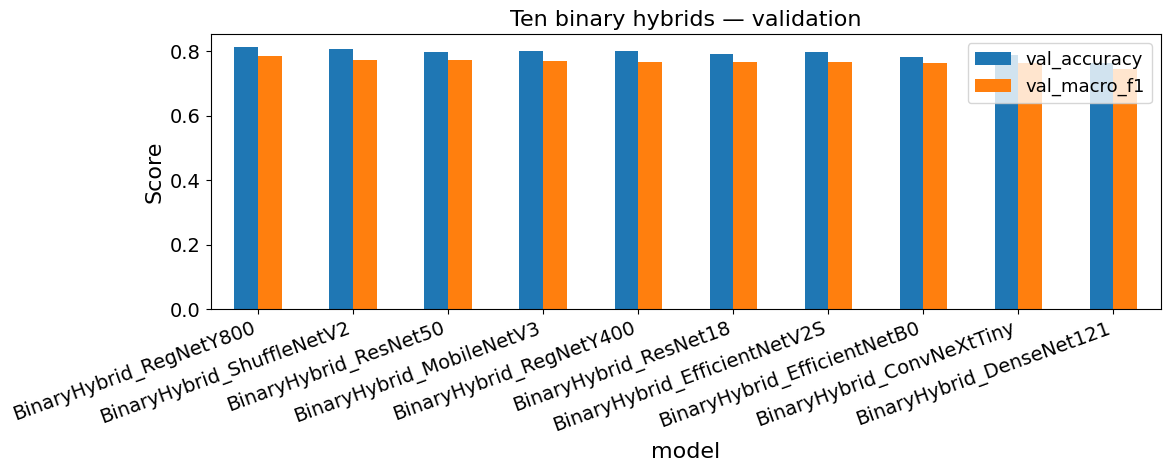

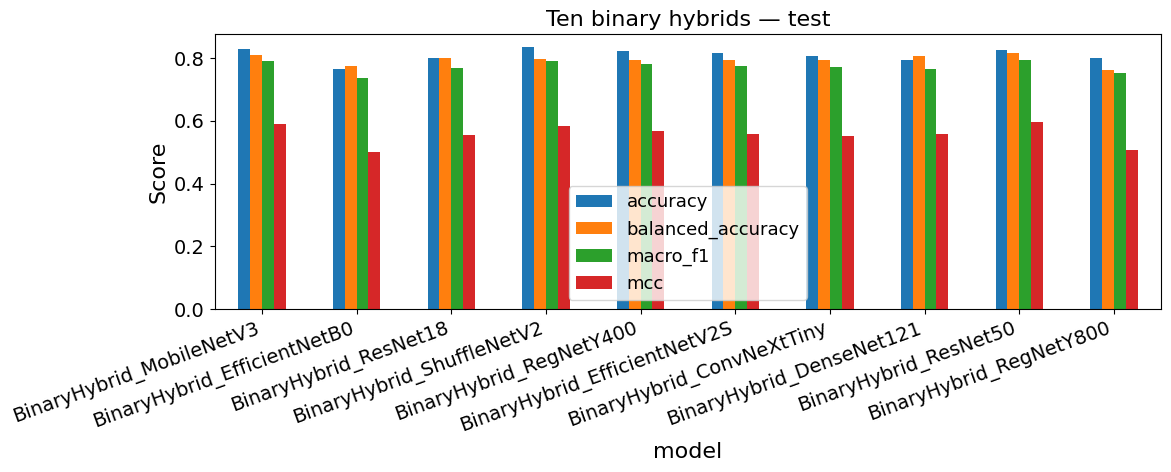

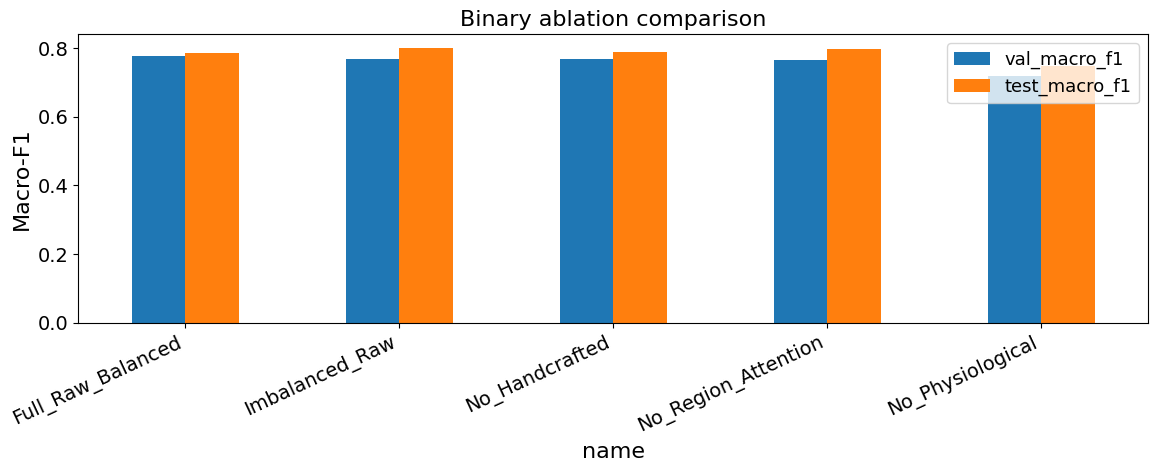

In [46]:
# CELL 31 — MODEL / ABLATION COMPARISON FIGURES
VAL_TABLE.set_index('model')[['val_accuracy','val_macro_f1']].plot(kind='bar',figsize=(12,5)); plt.ylabel('Score'); plt.title('Ten binary hybrids — validation'); plt.xticks(rotation=20,ha='right'); savefig('06_binary_model_validation')
TEST_TABLE.set_index('model')[['accuracy','balanced_accuracy','macro_f1','mcc']].plot(kind='bar',figsize=(12,5)); plt.ylabel('Score'); plt.title('Ten binary hybrids — test'); plt.xticks(rotation=20,ha='right'); savefig('07_binary_model_test')
ABL_TABLE.set_index('name')[['val_macro_f1','test_macro_f1']].plot(kind='bar',figsize=(12,5)); plt.ylabel('Macro-F1'); plt.title('Binary ablation comparison'); plt.xticks(rotation=25,ha='right'); savefig('08_binary_ablation')

In [47]:
# CELL 32 — FINAL TRAIN+VALIDATION PREPARATION
DEV_IDX=np.concatenate([TRAIN_IDX,VAL_IDX]); FINAL_PHYS_PREP=make_phys_preprocessor(DEV_IDX); FINAL_PHYS_PREP.fit(df.iloc[DEV_IDX][PHYS_COLS]); FINAL_PHYS=np.zeros((len(df),FINAL_PHYS_PREP.transform(df.iloc[DEV_IDX[:1]][PHYS_COLS]).shape[1]),dtype=np.float32); FINAL_PHYS[DEV_IDX]=FINAL_PHYS_PREP.transform(df.iloc[DEV_IDX][PHYS_COLS]).astype(np.float32); FINAL_PHYS[TEST_IDX]=FINAL_PHYS_PREP.transform(df.iloc[TEST_IDX][PHYS_COLS]).astype(np.float32)
RAW_HAND=np.zeros((len(df),len(HAND_NAMES)),dtype=np.float32)
for idx in tqdm(np.r_[DEV_IDX,TEST_IDX],desc='Final raw features'): RAW_HAND[idx]=raw_hand_features(get_raw(idx))
FINAL_HAND_SCALER=StandardScaler().fit(RAW_HAND[DEV_IDX]); FINAL_HAND=RAW_HAND.copy(); FINAL_HAND[DEV_IDX]=FINAL_HAND_SCALER.transform(RAW_HAND[DEV_IDX]).astype(np.float32); FINAL_HAND[TEST_IDX]=FINAL_HAND_SCALER.transform(RAW_HAND[TEST_IDX]).astype(np.float32)
joblib.dump(FINAL_PHYS_PREP,WEIGHT_DIR/'FINAL_phys_preprocessor.joblib'); joblib.dump(FINAL_HAND_SCALER,WEIGHT_DIR/'FINAL_hand_scaler.joblib')
dy=df.iloc[DEV_IDX].target.to_numpy(); d0=DEV_IDX[dy==0]; d1=DEV_IDX[dy==1]; rng=np.random.default_rng(SEED+999)
if bool(BEST_ABLATION['balanced']):
    d0b=rng.choice(d0,TARGET_PER_CLASS,replace=False) if len(d0)>TARGET_PER_CLASS else d0; base=np.concatenate([d0b,d1]); by=df.iloc[base].target.to_numpy(); ros=RandomOverSampler(sampling_strategy={0:TARGET_PER_CLASS,1:TARGET_PER_CLASS},random_state=SEED+999); res,_=ros.fit_resample(base.reshape(-1,1),by); FINAL_TRAIN_IDX=res.ravel().astype(int); rng.shuffle(FINAL_TRAIN_IDX)
else: FINAL_TRAIN_IDX=DEV_IDX.copy()
print('Final train counts:',np.bincount(df.iloc[FINAL_TRAIN_IDX].target,minlength=2).tolist())

Final raw features:   0%|          | 0/5202 [00:00<?, ?it/s]

Final train counts: [2000, 2000]


In [48]:
# CELL 33 — FINAL RETRAIN + TEST
class FinalDS(Dataset):
    def __init__(self,ids,train=False): self.ids=np.asarray(ids,dtype=int); self.tf=TRAIN_TF if train else EVAL_TF
    def __len__(self): return len(self.ids)
    def __getitem__(self,k):
        idx=int(self.ids[k]); return self.tf(Image.fromarray(get_raw(idx))),torch.tensor(FINAL_PHYS[idx],dtype=torch.float32),torch.tensor(FINAL_HAND[idx],dtype=torch.float32),torch.tensor(int(df.iloc[idx].target),dtype=torch.long),idx
final_loader=DataLoader(FinalDS(FINAL_TRAIN_IDX,True),BATCH_SIZE,shuffle=True); final_test=DataLoader(FinalDS(TEST_IDX,False),BATCH_SIZE*2,shuffle=False)
FINAL_MODEL=BinaryHybridNet(BACKBONE_MAP[BEST_MODEL_NAME],FINAL_PHYS.shape[1],FINAL_HAND.shape[1],bool(BEST_ABLATION['phys']),bool(BEST_ABLATION['hand']),bool(BEST_ABLATION['region'])).to(DEVICE); model_epoch=int(VAL_TABLE.loc[VAL_TABLE.model==BEST_MODEL_NAME,'best_epoch'].iloc[0]); abl_epoch=int(BEST_ABLATION['best_epoch']); FINAL_EPOCHS=max(1,round((model_epoch+abl_epoch)/2)); opt=torch.optim.Adam(FINAL_MODEL.parameters(),lr=LR_HEAD,weight_decay=WEIGHT_DECAY)
for ep in range(FINAL_EPOCHS):
    FINAL_MODEL.train(); losses=[]
    for x,p,h,y,_ in final_loader:
        x,p,h,y=x.to(DEVICE),p.to(DEVICE),h.to(DEVICE),y.to(DEVICE); opt.zero_grad(); logits,_,_=FINAL_MODEL(x,p,h); loss=F.cross_entropy(logits,y); loss.backward(); torch.nn.utils.clip_grad_norm_(FINAL_MODEL.parameters(),5); opt.step(); losses.append(loss.item())
    print(f'FINAL E{ep+1:02d}/{FINAL_EPOCHS}: loss={np.mean(losses):.4f}')
torch.save(FINAL_MODEL.state_dict(),WEIGHT_DIR/'FINAL_BINARY_MODEL.pt'); fy,fp,fids,fatt,femb=predict_loader(FINAL_MODEL,final_test,True); FINAL_METRICS=binary_metrics(fy,fp); FINAL_PRED=fp.argmax(1); pd.DataFrame([FINAL_METRICS]).to_csv(TABLE_DIR/'FINAL_binary_test_metrics.csv',index=False); pd.DataFrame(classification_report(fy,FINAL_PRED,target_names=CLASS_NAMES,output_dict=True,zero_division=0)).T.to_csv(TABLE_DIR/'FINAL_binary_classification_report.csv'); display(pd.DataFrame([FINAL_METRICS]))

FINAL E01/13: loss=0.6464
FINAL E02/13: loss=0.5776
FINAL E03/13: loss=0.4943
FINAL E04/13: loss=0.4656
FINAL E05/13: loss=0.4461
FINAL E06/13: loss=0.4272
FINAL E07/13: loss=0.4185
FINAL E08/13: loss=0.4062
FINAL E09/13: loss=0.3941
FINAL E10/13: loss=0.3863
FINAL E11/13: loss=0.3777
FINAL E12/13: loss=0.3771
FINAL E13/13: loss=0.3655


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,precision_class1,recall_sensitivity_class1,specificity_class0,f1_class1,npv_class0,false_positive_rate,false_negative_rate,youden_j,roc_auc,average_precision,kappa,mcc,brier_score,log_loss
0,0.788462,0.809735,0.751603,0.809735,0.76179,0.567308,0.855072,0.764398,0.682081,0.935897,0.235602,0.144928,0.61947,0.916762,0.818888,0.533107,0.55832,0.133285,0.408086


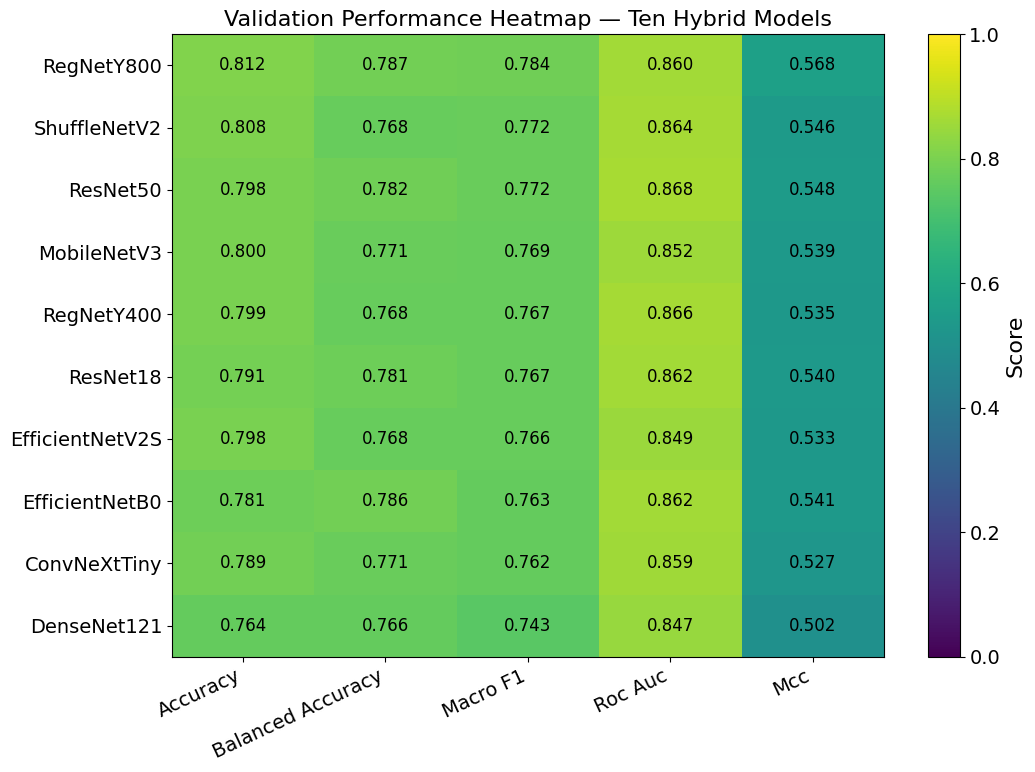

,model,best_epoch,overfit_gap,val_accuracy,val_balanced_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_precision_class1,val_recall_sensitivity_class1,...,npv_class0,false_positive_rate,false_negative_rate,youden_j,roc_auc,average_precision,kappa,mcc,brier_score,log_loss
0,BinaryHybrid_RegNetY800,14,0.052156,0.811900,0.787105,0.780773,0.787105,0.783741,0.691176,0.720859,...,0.879781,0.157068,0.318841,0.524091,0.887928,0.777336,0.505378,0.506848,0.124426,0.387937
1,BinaryHybrid_ShuffleNetV2,6,0.030888,0.808061,0.767604,0.778415,0.767604,0.772494,0.707237,0.659509,...,0.895722,0.123037,0.282609,0.594355,0.890792,0.792936,0.583551,0.583989,0.117438,0.369636
2,BinaryHybrid_ResNet50,6,0.018403,0.797505,0.782478,0.765506,0.782478,0.772248,0.655827,0.742331,...,0.919540,0.162304,0.202899,0.634798,0.892215,0.799265,0.588492,0.595735,0.123027,0.388974
3,BinaryHybrid_MobileNetV3,4,-0.002975,0.800384,0.771207,0.767702,0.771207,0.769391,0.676647,0.693252,...,0.912676,0.151832,0.224638,0.623530,0.887188,0.772989,0.586859,0.591524,0.121142,0.394291
4,BinaryHybrid_RegNetY400,8,0.026531,0.799424,0.768002,0.766676,0.768002,0.767330,0.677812,0.684049,...,0.898352,0.143979,0.268116,0.587905,0.897185,0.798977,0.564394,0.566455,0.118265,0.369701
5,BinaryHybrid_ResNet18,9,0.046288,0.790787,0.780932,0.759522,0.780932,0.767148,0.640625,0.754601,...,0.916418,0.196335,0.202899,0.600766,0.891437,0.791922,0.541831,0.554075,0.126620,0.392360
6,BinaryHybrid_EfficientNetV2S,6,0.028740,0.797505,0.768276,0.764392,0.768276,0.766254,0.671642,0.690184,...,0.901685,0.159686,0.253623,0.586691,0.886865,0.777311,0.553392,0.557486,0.122597,0.381125
7,BinaryHybrid_EfficientNetB0,9,0.052642,0.781190,0.786480,0.755194,0.786480,0.762543,0.615566,0.800613,...,0.911672,0.243455,0.202899,0.553646,0.887093,0.789871,0.481252,0.501102,0.143482,0.423097
8,BinaryHybrid_ConvNeXtTiny,5,0.020923,0.788868,0.771181,0.755836,0.771181,0.762017,0.644809,0.723926,...,0.907514,0.178010,0.231884,0.590105,0.879259,0.766014,0.544722,0.552190,0.131545,0.412691
9,BinaryHybrid_DenseNet121,6,0.046972,0.763916,0.765556,0.736909,0.765556,0.743496,0.594787,0.769939,...,0.928349,0.219895,0.166667,0.613438,0.887567,0.796946,0.537551,0.557266,0.138540,0.425615


In [49]:
master=VAL_TABLE.merge(
    TEST_TABLE,
    on="model",
    how="left",
    suffixes=("_valtable","_test")
)

master.to_csv(
    TABLE_DIR/"MASTER_10_model_metrics.csv",
    index=False
)

heat_cols=[
    "val_accuracy",
    "val_balanced_accuracy",
    "val_macro_f1",
    "val_roc_auc",
    "val_mcc"
]

matrix=VAL_TABLE.set_index("model")[heat_cols]

fig,ax=plt.subplots(figsize=(11,8))
im=ax.imshow(matrix.values,aspect="auto",vmin=0,vmax=1)

ax.set_xticks(
    np.arange(len(heat_cols)),
    [c.replace("val_","").replace("_"," ").title() for c in heat_cols],
    rotation=25,
    ha="right"
)
ax.set_yticks(
    np.arange(len(matrix.index)),
    [x.replace("BinaryHybrid_","") for x in matrix.index]
)

for r in range(matrix.shape[0]):
    for c in range(matrix.shape[1]):
        ax.text(
            c,r,
            f"{matrix.iloc[r,c]:.3f}",
            ha="center",
            va="center",
            fontsize=12
        )

ax.set_title(
    "Validation Performance Heatmap — Ten Hybrid Models",
    fontsize=16
)
fig.colorbar(im,ax=ax,label="Score")
savefig("09_ten_model_validation_heatmap")

display(master)

In [50]:
# CELL 34 — COMPLETE EXPORT / PAPER PACKAGE
summary=pd.DataFrame([
    {
        "stage":"Validation-selected model",
        "model":BEST_MODEL_NAME,
        **BEST_METRICS
    },
    {
        "stage":"Final retrained configuration",
        "model":BEST_MODEL_NAME,
        **FINAL_METRICS
    }
])

summary.to_csv(
    TABLE_DIR/"FINAL_binary_summary.csv",
    index=False
)
display(summary)

config={
    "task":"binary",
    "class0":"Non-FLD",
    "class1":"Mild FLD",
    "class2":"excluded",
    "split":"70:20:10",
    "seed":SEED,
    "image_size":IMG_SIZE,
    "clahe":False,
    "roi_crop_for_classifier":False,
    "smote":False,
    "train_balance":"2000/2000 train only",
    "models":MODEL_NAMES,
    "selected_model":BEST_MODEL_NAME,
    "selected_ablation":BEST_ABLATION["name"],
    "final_epochs":FINAL_EPOCHS,
    "evaluation_metric_count":len(binary_metrics(fy,fp)),
    "selection_rule":"validation Macro-F1 then AUC / overfit gap"
}

with open(
    TABLE_DIR/"experiment_config.json",
    "w"
) as f:
    json.dump(config,f,indent=2)

# Save a plain state-dict copy with an explicit best-model filename.
BEST_VALIDATION_PT=WEIGHT_DIR/"BEST_VALIDATION_SELECTED_MODEL.pt"
shutil.copy2(
    RUNS[BEST_MODEL_NAME]["checkpoint"],
    BEST_VALIDATION_PT
)

FINAL_PT=WEIGHT_DIR/"FINAL_BINARY_MODEL.pt"

,stage,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,precision_class1,recall_sensitivity_class1,specificity_class0,...,npv_class0,false_positive_rate,false_negative_rate,youden_j,roc_auc,average_precision,kappa,mcc,brier_score,log_loss
0,Validation-selected model,BinaryHybrid_RegNetY800,0.800000,0.762046,0.745086,0.762046,0.752399,0.610390,0.681159,0.842932,...,0.879781,0.157068,0.318841,0.524091,0.887928,0.777336,0.505378,0.506848,0.124426,0.387937
1,Final retrained configuration,BinaryHybrid_RegNetY800,0.788462,0.809735,0.751603,0.809735,0.761790,0.567308,0.855072,0.764398,...,0.935897,0.235602,0.144928,0.619470,0.916762,0.818888,0.533107,0.558320,0.133285,0.408086


In [51]:
# CONTINUATION — CREATE DOWNLOADABLE ZIP PACKAGES
# ZIP 1 — every generated figure, CSV, table, XAI result and weight.
ALL_OUTPUT_ZIP=shutil.make_archive(
    str(OUTPUT_DIR.parent/"Tongue_FLD_10MODEL_ALL_OUTPUTS"),
    "zip",
    OUTPUT_DIR
)

# ZIP 2 — compact package containing the best model and dependencies.
BEST_PACKAGE=OUTPUT_DIR/"best_model_package"
BEST_PACKAGE.mkdir(exist_ok=True)

package_files=[
    BEST_VALIDATION_PT,
    FINAL_PT,
    WEIGHT_DIR/"FINAL_phys_preprocessor.joblib",
    WEIGHT_DIR/"FINAL_hand_scaler.joblib",
    TABLE_DIR/"experiment_config.json",
    TABLE_DIR/"FINAL_binary_summary.csv",
    TABLE_DIR/"best_binary_test_metrics.csv",
]

for src in package_files:
    if Path(src).exists():
        shutil.copy2(src,BEST_PACKAGE/Path(src).name)

with open(BEST_PACKAGE/"README.txt","w") as f:
    f.write(
        "Validation-selected architecture: "+BEST_MODEL_NAME+"\n"
        "BEST_VALIDATION_SELECTED_MODEL.pt = checkpoint selected on validation data.\n"
        "FINAL_BINARY_MODEL.pt = final retrained state dictionary.\n"
    )

BEST_MODEL_ZIP=shutil.make_archive(
    str(OUTPUT_DIR.parent/"Tongue_FLD_BEST_MODEL_PACKAGE"),
    "zip",
    BEST_PACKAGE
)

print("ALL OUTPUTS:",ALL_OUTPUT_ZIP)
print("BEST MODEL ZIP:",BEST_MODEL_ZIP)
print("Selected model:",BEST_MODEL_NAME)
print("Metrics available:",len(binary_metrics(fy,fp)))
print("Weights:",len(list(WEIGHT_DIR.glob("*"))))
print("Tables:",len(list(TABLE_DIR.glob("*"))))
print(
    "Figures:",
    len(list(FIG_DIR.glob("*.png"))) +
    len(list(XAI_DIR.glob("*.png")))
)

ALL OUTPUTS: /kaggle/working/Tongue_FLD_10MODEL_ALL_OUTPUTS.zip
BEST MODEL ZIP: /kaggle/working/Tongue_FLD_BEST_MODEL_PACKAGE.zip
Selected model: BinaryHybrid_RegNetY800
Metrics available: 19
Weights: 22
Tables: 37
Figures: 17


In [52]:
# CLICKABLE DOWNLOAD LINKS — RUN AFTER EXPORT CELL
print("1) Complete paper outputs ZIP")
display(FileLink(ALL_OUTPUT_ZIP))

print("\n2) Best-model package ZIP")
display(FileLink(BEST_MODEL_ZIP))

print("\n3) Validation-selected PyTorch checkpoint")
display(FileLink(str(BEST_VALIDATION_PT)))

print("\n4) Final retrained PyTorch model")
display(FileLink(str(FINAL_PT)))

1) Complete paper outputs ZIP


/kaggle/working/Tongue_FLD_10MODEL_ALL_OUTPUTS.zip


2) Best-model package ZIP


/kaggle/working/Tongue_FLD_BEST_MODEL_PACKAGE.zip


3) Validation-selected PyTorch checkpoint


/kaggle/working/tongue_fld_q1_v8_2_ten_models/weights/BEST_VALIDATION_SELECTED_MODEL.pt


4) Final retrained PyTorch model


/kaggle/working/tongue_fld_q1_v8_2_ten_models/weights/FINAL_BINARY_MODEL.pt